In [1]:
from pathlib import Path
import pandas as pd
import numpy as np


In [2]:
print("Pandas version:", pd.__version__)


Pandas version: 2.3.3


In [3]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Raw data directory exists:", RAW_DATA_DIR.exists()) 

Project root: c:\Users\Psper\NFL_Big_Data_Bowl
Raw data directory exists: True


In [ ]:
csv_files = list(RAW_DATA_DIR.glob("*.csv"))

In [5]:
inventory = pd.DataFrame([
    {
        "file": file.name,
        "size_mb": round(file.stat().st_size / 1_000_000, 2)
    }
    for file in csv_files
])

inventory

,file,size_mb
0,combine_results.csv,0.04
1,combine_tracking.csv,83.79
2,games.csv,0.04
3,game_tracking_2023.csv,335.46
4,game_tracking_2024.csv,717.95
5,game_tracking_2025.csv,1022.58
6,players.csv,0.05
7,player_career_successes.csv,0.01
8,player_play.csv,146.88


In [7]:
#Check column names for our csv files
for file in csv_files:
    columns = pd.read_csv(file, nrows=0).columns.tolist()

    print(f"\n{file.name}")
    print(f"Number of columns: {len(columns)}")
    print(columns)


combine_results.csv
Number of columns: 18
['draft_year', 'nfl_id', 'combine_position', 'combine_height', 'combine_weight', 'hand_size', 'arm_length', 'wing_span', 'ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone', 'short_shuttle', 'bench_reps', 'ngs_athleticism_score', 'ngs_college_production_score', 'ngs_final_score']

combine_tracking.csv
Number of columns: 14
['draft_year', 'event_id', 'nfl_id', 'entity_type', 'time', 'drill_type', 'drill_name', 'attempt', 'x', 'y', 's', 'a', 'dis', 'dir']

games.csv
Number of columns: 7
['game_id', 'game_key', 'season', 'season_type', 'week', 'home_team_abbr', 'visitor_team_abbr']

game_tracking_2023.csv
Number of columns: 12
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']

game_tracking_2024.csv
Number of columns: 12
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']

game_tracking_2025.csv
Number of columns: 12
['game_id', 'play_id', 'nfl_id', 'time', 'x

We will go one by one audting the data through each csv respectfully

In [8]:
#Start with the combine.csv which stores the combine results for the players in our scope

combine = pd.read_csv(RAW_DATA_DIR / "combine_results.csv")

combine.head()

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


In [9]:
#Check size of the combine csv
combine.shape

#Check datatypes
combine.info()
#Check for missing values
combine.isnull().sum()

#Check for duplicate rows
combine.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   draft_year                    510 non-null    int64  
 1   nfl_id                        510 non-null    int64  
 2   combine_position              510 non-null    object 
 3   combine_height                510 non-null    float64
 4   combine_weight                510 non-null    int64  
 5   hand_size                     510 non-null    float64
 6   arm_length                    510 non-null    float64
 7   wing_span                     510 non-null    float64
 8   ten_yd_split                  425 non-null    float64
 9   forty                         424 non-null    float64
 10  vertical                      438 non-null    float64
 11  broad_jump                    423 non-null    float64
 12  three_cone                    180 non-null    float64
 13  short

0

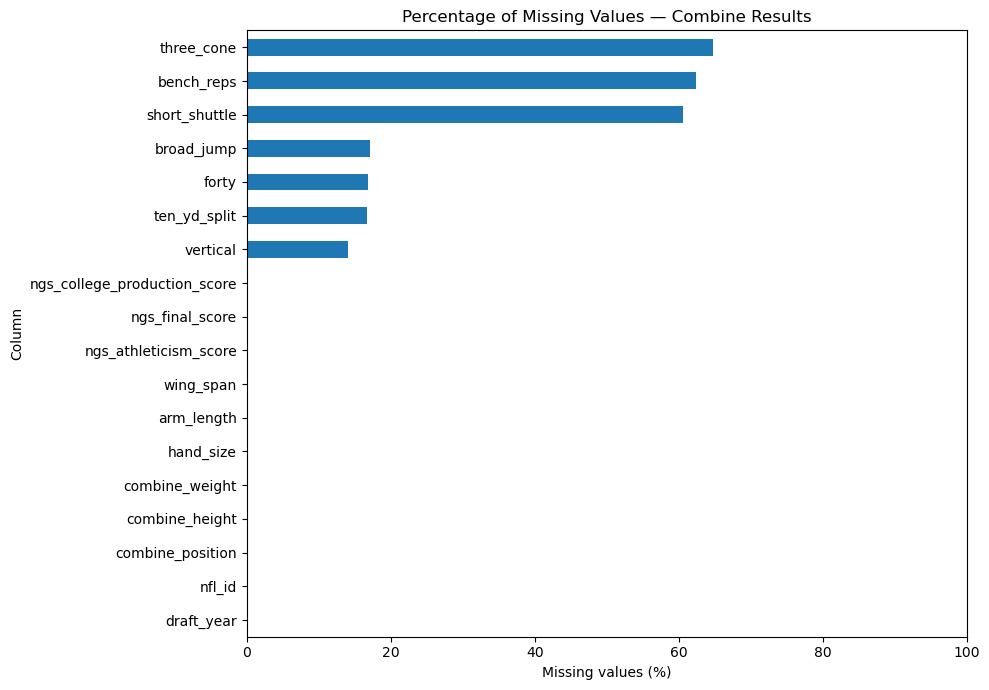

In [10]:
#Plot missing value percent from combine csv

import matplotlib.pyplot as plt

missing_pct = combine.isnull().mean().mul(100).sort_values()

missing_pct.plot(kind="barh", figsize=(10, 7))

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Percentage of Missing Values — Combine Results")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


In [11]:
#For all the drills there are missing values, we must investiagte if there is a trend of a particular position skipping a particular drill

drills = [
    "ten_yd_split",
    "forty",
    "vertical",
    "broad_jump",
    "three_cone",
    "short_shuttle",
    "bench_reps",
]

missing_by_position = (
    combine.groupby("combine_position")[drills]
    .agg(lambda col: col.isna().mean() * 100)
    .round(1)
)

missing_by_position


,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps
combine_position,,,,,,,
DB,14.8,14.8,13.9,19.7,79.5,73.0,63.1
DL,20.3,20.3,13.6,17.8,63.6,61.0,54.2
OL,20.7,21.5,17.4,19.0,49.6,47.1,56.2
TE,19.0,19.0,16.7,16.7,57.1,52.4,71.4
WR,9.3,9.3,10.3,11.2,69.2,64.5,73.8


In [12]:
# Some drill inherintely have more players opt to skip, 
# we  can check if there is a significant difference in missing values across different positions for each drill

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

results = []

for drill in drills:
    # Rows = positions; columns = observed vs. missing
    table = pd.crosstab(
        combine["combine_position"],
        combine[drill].isna()
    )

    # Ensure both outcome categories are present
    table = table.reindex(columns=[False, True], fill_value=0)

    chi2, p_value, dof, expected = chi2_contingency(table)

    # Cramer's V: strength of association
    n = table.to_numpy().sum()
    min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    results.append({
        "drill": drill,
        "missing_pct": combine[drill].isna().mean() * 100,
        "chi2": chi2,
        "degrees_of_freedom": dof,
        "p_value": p_value,
        "cramers_v": cramers_v,
    })

results_df = pd.DataFrame(results)

# Correct the seven p-values for multiple testing
results_df["p_value_holm"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df = results_df.sort_values("p_value_holm")

results_df.round(4)


,drill,missing_pct,chi2,degrees_of_freedom,p_value,cramers_v,p_value_holm
4,three_cone,64.7059,25.8653,4,0.0000,0.2252,0.0002
5,short_shuttle,60.5882,18.8918,4,0.0008,0.1925,0.0050
6,bench_reps,62.3529,12.7734,4,0.0124,0.1583,0.0622
0,ten_yd_split,16.6667,7.1576,4,0.1278,0.1185,0.4119
1,forty,16.8627,7.7058,4,0.1030,0.1229,0.4119
2,vertical,14.1176,2.6044,4,0.6260,0.0715,0.9417
3,broad_jump,17.0588,3.5465,4,0.4708,0.0834,0.9417


Three-cone and short shuttle: Missingness is statistically associated with position. We should examine which specific positions differ using the pairwise tests.



Bench press: There is some evidence of an overall difference before multiple-testing correction, but it does not meet our adjusted 5% significance threshold.



Other four drills: We don't have statistically significant evidence that missingness differs by position. That doesn't prove the rates are identical.

In [13]:
#From chi-squared test of independence across groups we see that 
#Pairwise positional comparisons
from itertools import combinations
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

pairwise_results = []
positions = sorted(combine["combine_position"].dropna().unique())

for drill in drills:
    for pos1, pos2 in combinations(positions, 2):
        group1 = combine.loc[combine["combine_position"] == pos1, drill]
        group2 = combine.loc[combine["combine_position"] == pos2, drill]

        missing_counts = [
            group1.isna().sum(),
            group2.isna().sum()
        ]
        sample_sizes = [len(group1), len(group2)]

        _, p_value = proportions_ztest(
            count=missing_counts,
            nobs=sample_sizes
        )

        rate1 = missing_counts[0] / sample_sizes[0]
        rate2 = missing_counts[1] / sample_sizes[1]

        pairwise_results.append({
            "drill": drill,
            "position_1": pos1,
            "position_2": pos2,
            "missing_pct_1": rate1 * 100,
            "missing_pct_2": rate2 * 100,
            "difference_pp": (rate1 - rate2) * 100,
            "p_value": p_value
        })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df["p_value_holm"] = multipletests(
    pairwise_df["p_value"],
    method="holm"
)[1]

pairwise_df["significant"] = pairwise_df["p_value_holm"] < 0.05

In [14]:
#Results
significant_pairs = (
    pairwise_df.loc[pairwise_df["significant"]]
    .sort_values("p_value_holm")
)

display(significant_pairs.round(3))

,drill,position_1,position_2,missing_pct_1,missing_pct_2,difference_pp,p_value,p_value_holm,significant
41,three_cone,DB,OL,79.508,49.587,29.921,0.0,0.000,True
51,short_shuttle,DB,OL,72.951,47.107,25.843,0.0,0.003,True


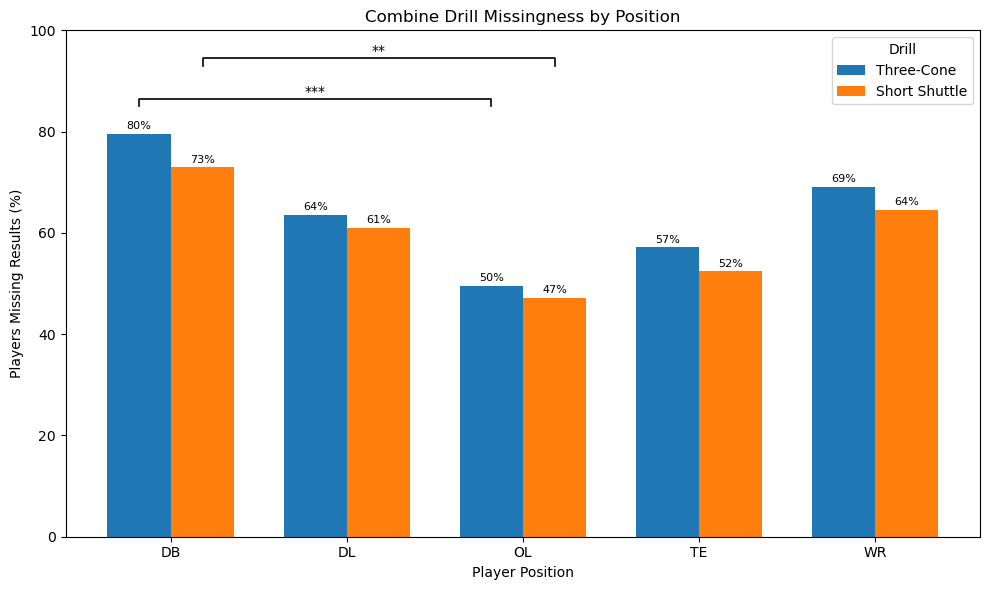

In [19]:
import matplotlib.pyplot as plt
import numpy as np

selected_drills = ["three_cone", "short_shuttle"]

plot_data = (
    combine.groupby("combine_position")[selected_drills]
    .agg(lambda col: col.isna().mean() * 100)
)

plot_data.columns = ["Three-Cone", "Short Shuttle"]

fig, ax = plt.subplots(figsize=(10, 6))

positions = plot_data.index.tolist()
x = np.arange(len(positions))
width = 0.36

bars1 = ax.bar(
    x - width / 2,
    plot_data["Three-Cone"],
    width,
    label="Three-Cone"
)

bars2 = ax.bar(
    x + width / 2,
    plot_data["Short Shuttle"],
    width,
    label="Short Shuttle"
)

ax.set_title("Combine Drill Missingness by Position")
ax.set_xlabel("Player Position")
ax.set_ylabel("Players Missing Results (%)")
ax.set_xticks(x)
ax.set_xticklabels(positions)
ax.set_ylim(0, 100)
ax.legend(title="Drill")

# Annotate each bar with its missingness percentage
ax.bar_label(bars1, fmt="%.0f%%", padding=2, fontsize=8)
ax.bar_label(bars2, fmt="%.0f%%", padding=2, fontsize=8)

# Significant DB vs OL comparisons
def add_bracket(ax, x1, x2, y, label, h=1.5):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        color="black",
        linewidth=1.2
    )
    ax.text(
        (x1 + x2) / 2,
        y + h,
        label,
        ha="center",
        va="bottom"
    )

db_idx = positions.index("DB")
ol_idx = positions.index("OL")

# Bar centers within each position group
add_bracket(
    ax,
    db_idx - width / 2,
    ol_idx - width / 2,
    85,
    "***"
)

add_bracket(
    ax,
    db_idx + width / 2,
    ol_idx + width / 2,
    93,
    "**"
)

plt.tight_layout()
plt.show()

Missing combine results were significantly associated with player position for the three-cone and short-shuttle drills. Defensive backs had higher missingness rates than offensive linemen for both the three-cone (79.5% vs. 49.6%, adjusted p < 0.001) and short shuttle (73.0% vs. 47.1%, adjusted p = 0.003), with both differences remaining significant after Holm correction across 70 pairwise comparisons. These findings suggest that combine data missingness may be position-dependent, although the data alone cannot establish whether players intentionally skipped these drills.

In [20]:
#Check for duplicates
print(combine.duplicated().sum())
print(combine["nfl_id"].duplicated().sum())
print(combine.duplicated(["nfl_id", "draft_year"]).sum())


0
0
0


There are no duplicate entries in the combine csv

In [21]:
#Check for suspicous measurement values
combine.describe().round(2)

,draft_year,nfl_id,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
count,510.00,510.00,510.00,510.00,510.00,510.00,510.00,425.00,424.00,438.00,423.00,180.00,201.00,192.00,510.00,509.00,509.00
mean,2024.03,57331.32,74.58,248.38,9.57,32.41,78.47,1.63,4.73,33.81,118.15,7.31,4.47,21.72,72.45,67.48,70.33
std,0.81,979.51,2.63,53.25,0.60,1.42,3.27,0.12,0.31,4.14,9.06,0.39,0.25,5.72,10.61,8.32,7.53
min,2023.00,55867.00,68.12,154.00,8.00,28.50,69.00,1.46,4.28,23.00,93.00,6.57,3.93,8.00,51.00,50.00,52.00
25%,2023.00,56273.50,72.62,198.00,9.12,31.38,76.25,1.54,4.47,31.00,111.00,7.00,4.28,17.00,65.00,61.00,65.00
50%,2024.00,57290.00,75.00,245.50,9.50,32.38,78.50,1.59,4.62,34.00,120.00,7.29,4.45,22.00,73.00,66.00,70.00
75%,2025.00,58302.75,76.50,304.00,10.00,33.50,80.84,1.74,5.01,37.00,125.00,7.62,4.68,26.00,80.00,73.00,75.00
max,2025.00,59278.00,80.62,374.00,11.62,36.88,88.25,1.96,5.48,44.00,138.00,8.19,5.03,39.00,99.00,99.00,94.00


In [22]:
#Check extreme values
combine.loc[
    combine["forty"].isin([
        combine["forty"].min(),
        combine["forty"].max()
    ]),
    ["nfl_id", "draft_year", "combine_position", "forty"]
]

,nfl_id,draft_year,combine_position,forty
123,56450,2023,OL,5.48
152,56344,2023,OL,5.48
463,58232,2025,DB,4.28


All these values are valid, the 40 yard dash by the db is valid, and o linemen run slow sometimes.

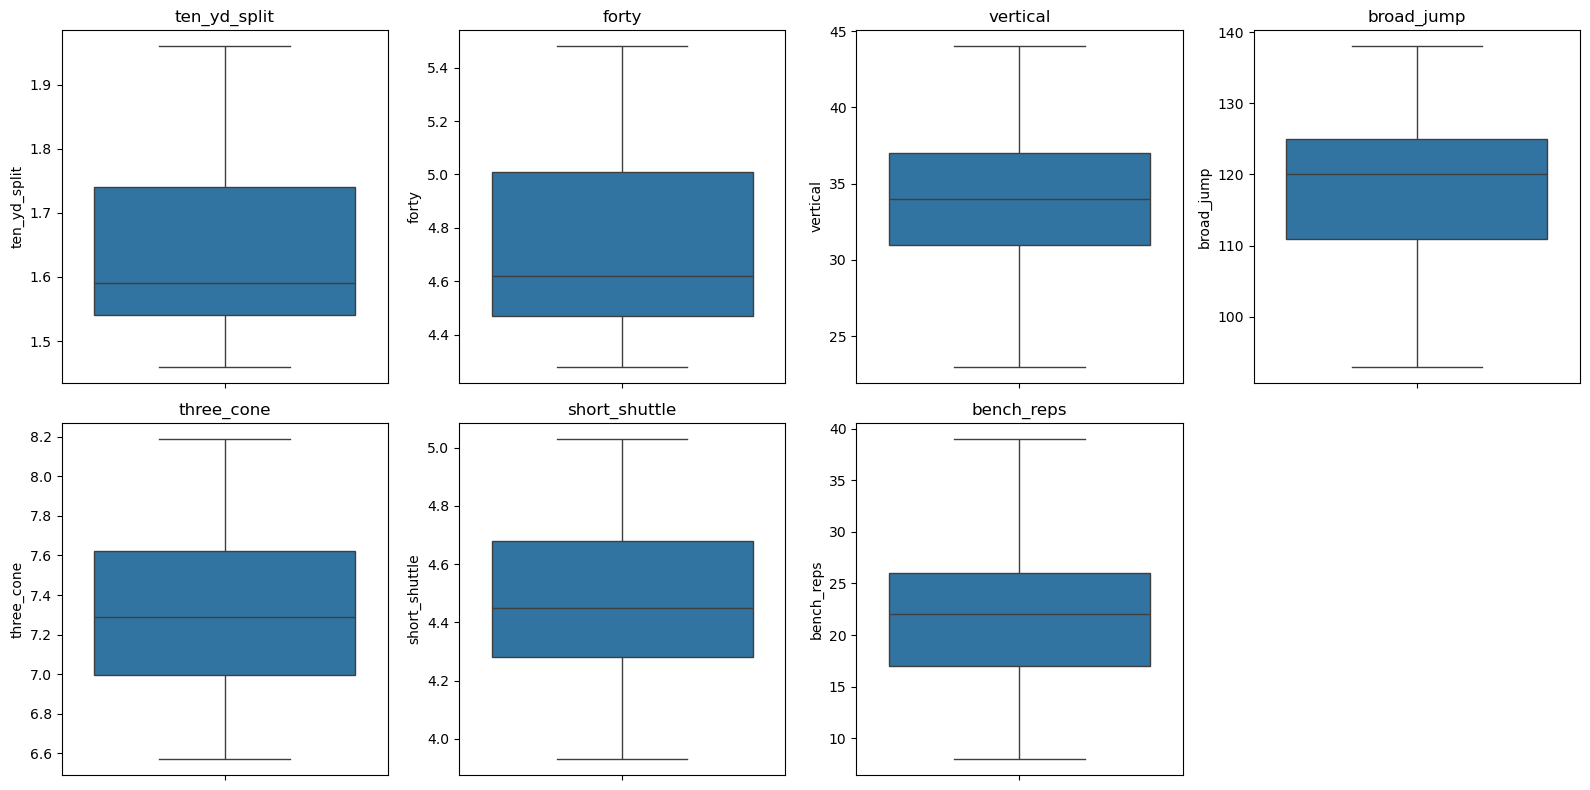

In [23]:
#Check for outliers
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, drill in zip(axes.flat, drills):
    sns.boxplot(data=combine, y=drill, ax=ax)
    ax.set_title(drill)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()


From a quick obsevation there is no outliers flagging any potetnial problems.


### Moving on the combine_tracking.csv

Check the general strcuture of the data

In [25]:
combine_tracking = pd.read_csv(RAW_DATA_DIR / "combine_tracking.csv")

combine_tracking.shape

(463189, 14)

In [27]:
combine_tracking.head()


,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [28]:
combine_tracking.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463189 entries, 0 to 463188
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   draft_year   463189 non-null  int64  
 1   event_id     463189 non-null  object 
 2   nfl_id       463189 non-null  int64  
 3   entity_type  463189 non-null  object 
 4   time         463189 non-null  object 
 5   drill_type   463189 non-null  object 
 6   drill_name   463189 non-null  object 
 7   attempt      463189 non-null  int64  
 8   x            463189 non-null  float64
 9   y            463189 non-null  float64
 10  s            463189 non-null  float64
 11  a            463189 non-null  float64
 12  dis          463189 non-null  float64
 13  dir          463189 non-null  float64
dtypes: float64(6), int64(3), object(5)
memory usage: 49.5+ MB


The tracking combine data measures in 0.1 second increments, ie 10hz for each player during the drill. the first recording is the start of the drill and the last measurement is the very end of the timer of the drill.

In [29]:
combine_tracking["drill_type"].value_counts()
combine_tracking["drill_name"].value_counts()

drill_name
FORTY_YARD_DASH                                 41500
GAUNTLET_DRILL                                  38228
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION    21569
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE          18087
THREE_CONE_DRILL                                15951
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION     12845
OVER_SHOULDER_ADJUST                            12149
LINE_DRILL                                      11895
FOUR_BAG_AGILITY_DRILL                          11709
SHORT_SHUTTLE                                   11690
PASS_RUSH_DROP                                  10752
POST_CORNER_ROUTE_RIGHT                         10517
PASS_RUSH_DRILL                                 10285
W_DRILL                                         10214
DAGGER_ROUTE_LEFT                                9917
GO_ROUTE_RIGHT                                   9843
SLOT_SAIL_ROUTE_RIGHT                            9524
TERYL_AUSTIN_DRILL_2                             9514
BOX_DRILL        

In [30]:
#Check player count and events per drill
drill_summary = (
    combine_tracking.groupby("drill_name")
    .agg(
        players=("nfl_id", "nunique"),
        events=("event_id", "nunique"),
        observations=("nfl_id", "size")
    )
    .sort_values("players", ascending=False)
)

drill_summary

,players,events,observations
drill_name,,,
FORTY_YARD_DASH,418,793,41500
GAUNTLET_DRILL,267,404,38228
SHORT_SHUTTLE,170,223,11690
THREE_CONE_DRILL,160,203,15951
OVER_SHOULDER_ADJUST,130,135,12149
BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL,122,124,8422
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,122,241,21569
BOX_DRILL,122,125,9439
W_DRILL,121,124,10214


Not every player does every drill


In [31]:
#Check overlap from combine results and tracking data
combine_ids = set(combine["nfl_id"])
tracking_ids = set(combine_tracking["nfl_id"])

print("Combine players:", len(combine_ids))
print("Tracking players:", len(tracking_ids))
print("Players in both:", len(combine_ids & tracking_ids))
print("Combine only:", len(combine_ids - tracking_ids))
print("Tracking only:", len(tracking_ids - combine_ids))


Combine players: 510
Tracking players: 510
Players in both: 510
Combine only: 0
Tracking only: 0


There is a perfect match between the two datasets by playerid

In [32]:
drill_pairs = {
    "forty": "FORTY_YARD_DASH",
    "three_cone": "THREE_CONE_DRILL",
    "short_shuttle": "SHORT_SHUTTLE"
}

coverage = []

for measurement, drill in drill_pairs.items():
    measured_ids = set(combine.loc[combine[measurement].notna(), "nfl_id"])
    tracked_ids = set(combine_tracking.loc[combine_tracking["drill_name"] == drill, "nfl_id"])

    coverage.append({
        "drill": drill,
        "measured": len(measured_ids),
        "tracked": len(tracked_ids),
        "both": len(measured_ids & tracked_ids),
        "measured_only": len(measured_ids - tracked_ids),
        "tracked_only": len(tracked_ids - measured_ids)
    })

pd.DataFrame(coverage)

,drill,measured,tracked,both,measured_only,tracked_only
0,FORTY_YARD_DASH,424,418,418,6,0
1,THREE_CONE_DRILL,180,160,150,30,10
2,SHORT_SHUTTLE,201,170,160,41,10


While there is perfect overlap between datasets some players still did not participate in all activities. 

40 yard dash has 98.6 percent coverage
three-cone has 83.3 percent coverage
short shuttle has 79.6 percent coverage 


In [33]:
#Check what is a unique tracking event
event_structure = combine_tracking.groupby("event_id").agg(
    players=("nfl_id", "nunique"),
    drills=("drill_name", "nunique"),
    attempts=("attempt", "nunique")
)

event_structure.describe()

,players,drills,attempts
count,6310.0,6310.0,6310.0
mean,1.0,1.0,1.0
std,0.0,0.0,0.0
min,1.0,1.0,1.0
25%,1.0,1.0,1.0
50%,1.0,1.0,1.0
75%,1.0,1.0,1.0
max,1.0,1.0,1.0


Heirarchy 510 players -> 6,310 drill events total -> 463,189 tracking obersevations

In [ ]:
#Check how timestamp data is imputed
#convert the timestamps 
combine_tracking["time"] = pd.to_datetime(combine_tracking["time"])

In [35]:
#Check the interval between observations
tracking_sorted = combine_tracking.sort_values(["event_id", "time"]).copy()

tracking_sorted["dt"] = (
    tracking_sorted.groupby("event_id")["time"]
    .diff()
    .dt.total_seconds()
)

tracking_sorted["dt"].describe()


count    456879.000000
mean          0.092975
std           0.025557
min           0.000000
25%           0.100000
50%           0.100000
75%           0.100000
max           0.100000
Name: dt, dtype: float64

### The tracking data is 10hz(one every 0.1 seconds)
The variation occurs due to different ending recordings

In [36]:
#How many are zero vs 0.1
tracking_sorted["dt"].value_counts().sort_index()

dt
0.0     32095
0.1    424784
Name: count, dtype: int64

In [37]:
#Check for duplicates
combine_tracking.duplicated().sum()

0

no duplicates

In [38]:
duplicate_times = combine_tracking[
    combine_tracking.duplicated(["event_id", "time"], keep=False)
]

duplicate_times.sort_values(["event_id", "time"]).head(20)

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
142676,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.200,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.225789,23.279475,0.654606,2.028745,0.003011,159.655843
142745,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.200,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.338374,23.570836,0.170420,0.063381,0.000267,194.447420
142677,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.300,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.248583,23.207858,0.869065,2.352696,0.005155,158.848827
142746,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.300,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.334381,23.554161,0.172550,0.061234,0.000279,192.491013
142678,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.400,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.261790,23.085225,1.173742,2.670111,0.015040,162.034010
142747,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.400,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.330905,23.537150,0.174755,0.059142,0.000290,190.643340
142679,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.500,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.304021,22.958316,1.453305,2.893052,0.016205,159.101506
142748,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.500,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.327922,23.519816,0.177016,0.057103,0.000301,188.899125
142680,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.600,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.354266,22.811946,1.785264,3.633536,0.021572,152.304800
142749,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.600,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.325422,23.502177,0.179313,0.055118,0.000311,187.252883


### There is not just player tracking data but also ball tracking data

Heirarchy player -> Drill even -> Player tracking and Ball tracking -> timestampled observations

In [39]:
combine_tracking["entity_type"].value_counts()

entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64

There is 93.1 percent of the observations are from player data the rest are from ball tracking

In [40]:
combine_tracking.duplicated(
    ["event_id", "entity_type", "time"]
).sum()

0

In [41]:
tracking_sorted = combine_tracking.sort_values(
    ["event_id", "entity_type", "time"]
).copy()

tracking_sorted["dt"] = (
    tracking_sorted.groupby(["event_id", "entity_type"])["time"]
    .diff()
    .dt.total_seconds()
)

tracking_sorted["dt"].value_counts().sort_index()

dt
0.1    456328
Name: count, dtype: int64

All oberservations are exactly 0.1 seconds apart


In [43]:
#Inspecting the numeric data structure
combine_tracking.groupby("entity_type")[
    ["x", "y", "s", "a", "dis", "dir"]
].describe().round(3)

x                                                  \
                count    mean     std     min     25%     50%     75%   
entity_type                                                             
BALL          32095.0  32.895  14.406  13.583  22.242  27.478  40.912   
PLAYER       431094.0  45.109  17.239   1.300  36.231  44.667  48.433   

                             y          ...    dis               dir           \
                 max     count    mean  ...    75%     max     count     mean   
entity_type                             ...                                     
BALL          81.881   32095.0  25.190  ...  1.999  45.285   32095.0  165.409   
PLAYER       103.900  431094.0  23.954  ...  0.490   1.440  431094.0  148.496   

                                                               
                std    min     25%      50%      75%      max  
entity_type                                                    
BALL         92.109  0.016  84.511  127.477  265.313  359.902  
PLAYER       96.632  0.000  88.142  109.552  226.378  360.000  

[2 rows x 48 columns]

In [44]:
combine_tracking.groupby("entity_type")[
    ["s", "a", "dis"]
].agg(["min", "mean", "median", "std", "max"]).round(3)

s                                 a                       \
               min   mean median    std     max  min   mean median    std   
entity_type                                                                 
BALL         0.006  7.818  4.221  7.644  25.794  0.0  2.564  1.823  2.913   
PLAYER       0.000  4.931  4.977  2.843  11.854  0.0  2.832  2.566  1.847   

                     dis                               
                max  min   mean median    std     max  
entity_type                                            
BALL         44.607  0.0  1.074  0.171  1.829  45.285  
PLAYER       10.718  0.0  0.299  0.218  0.284   1.440

In [45]:
combine_tracking.nlargest(10, "dis")[
    ["event_id", "entity_type", "drill_name", "time", "s", "a", "dis"]
]

,event_id,entity_type,drill_name,time,s,a,dis
118230,20250301100700_1740866676846_000,BALL,COMEBACK_ROUTE_RIGHT,2025-03-01 22:04:30.700,2.522485,0.935003,45.285317
73363,20250301100800_1740874616438_000,BALL,CIRCUS_ROUTE_LEFT,2025-03-02 00:16:51.600,22.436798,0.088770,35.110196
135751,20250301100700_1740866664422_000,BALL,COMEBACK_ROUTE_RIGHT,2025-03-01 22:04:19.300,1.629627,2.867560,34.837891
71139,20250301100700_1740864795627_000,BALL,SPEED_OUT_ROUTE_LEFT,2025-03-01 21:33:14.000,4.228181,1.818115,34.018407
100318,20250301100800_1740874486084_000,BALL,DAGGER_ROUTE_LEFT,2025-03-02 00:14:43.200,2.686012,4.182231,32.248844
93175,20250301100700_1740865154761_000,BALL,DAGGER_ROUTE_LEFT,2025-03-01 21:39:12.700,2.862532,3.027289,32.121681
47380,20250301100700_1740865133934_000,BALL,DAGGER_ROUTE_LEFT,2025-03-01 21:38:51.100,2.710268,0.543411,31.781334
139799,20250228100500_1740792073446_000,BALL,WHEEL_ROUTE_LEFT,2025-03-01 01:21:11.600,3.352135,8.123480,31.152561
174231,20250301100800_1740876046245_000,BALL,COMEBACK_ROUTE_RIGHT,2025-03-02 00:40:44.100,3.727615,0.367907,29.890681
134941,20250301100700_1740866963975_000,BALL,POST_CORNER_ROUTE_RIGHT,2025-03-01 22:09:21.900,2.522970,7.457391,28.026221


We can calculate actual cordinate displacement


In [46]:
event = combine_tracking.loc[
    combine_tracking["dis"].idxmax(), "event_id"
]

ball_event = combine_tracking[
    (combine_tracking["event_id"] == event) &
    (combine_tracking["entity_type"] == "BALL")
].sort_values("time").copy()

ball_event["calculated_dis"] = np.sqrt(
    ball_event["x"].diff()**2 +
    ball_event["y"].diff()**2
)

ball_event.nlargest(10, "dis")[
    ["time", "x", "y", "s", "dis", "calculated_dis"]
]

,time,x,y,s,dis,calculated_dis
118230,2025-03-01 22:04:30.700,44.899389,-5.240794,2.522485,45.285317,7.506777
118215,2025-03-01 22:04:29.200,19.362591,24.506416,23.697070,6.043221,2.907547
118216,2025-03-01 22:04:29.300,20.940750,22.733800,23.659309,4.009519,2.373342
118217,2025-03-01 22:04:29.400,22.524651,20.973347,23.593516,3.987330,2.368108
118218,2025-03-01 22:04:29.500,24.111387,19.227423,23.499723,3.953579,2.359233
118219,2025-03-01 22:04:29.600,25.694633,17.497100,23.381783,3.904812,2.345355
118220,2025-03-01 22:04:29.700,27.283572,15.786851,23.240196,3.863880,2.334454
118221,2025-03-01 22:04:29.800,28.866074,14.095300,23.077957,3.802483,2.316389
118222,2025-03-01 22:04:29.900,30.446030,12.425046,22.897682,3.743529,2.299132
118223,2025-03-01 22:04:30.000,32.021571,10.776725,22.702621,3.680198,2.280196


In [47]:
player_tracking = tracking_sorted[
    tracking_sorted["entity_type"] == "PLAYER"
].copy()

player_tracking["calculated_speed"] = (
    np.sqrt(
        player_tracking.groupby("event_id")["x"].diff()**2 +
        player_tracking.groupby("event_id")["y"].diff()**2
    ) / 0.1
)

player_tracking[["s", "calculated_speed"]].describe().round(3)

,s,calculated_speed
count,431094.000,424784.000
mean,4.931,4.980
std,2.843,2.816
min,0.000,0.000
25%,2.440,2.539
50%,4.977,5.011
75%,7.296,7.333
max,11.854,12.005


In [48]:
speed_comparison = player_tracking[
    ["s", "calculated_speed"]
].dropna().copy()

speed_comparison["absolute_error"] = (
    speed_comparison["s"] -
    speed_comparison["calculated_speed"]
).abs()

print("Correlation:", speed_comparison["s"].corr(speed_comparison["calculated_speed"]))
print("Mean absolute error:", speed_comparison["absolute_error"].mean())
print("Median absolute error:", speed_comparison["absolute_error"].median())
print("95th percentile error:", speed_comparison["absolute_error"].quantile(0.95))

Correlation: 0.9982817597059045
Mean absolute error: 0.12537664039950439
Median absolute error: 0.10000000300000189
95th percentile error: 0.32408594537428204


Our calculated speeds from the x,y cordinates matches the recorded speed extremely well

In [49]:
#looking at the duration of the drill times
event_durations = (
    combine_tracking[combine_tracking["entity_type"] == "PLAYER"]
    .groupby(["event_id", "drill_name"])
    .agg(
        start=("time", "min"),
        end=("time", "max"),
        frames=("time", "size")
    )
    .reset_index()
)

event_durations["duration"] = (
    event_durations["end"] - event_durations["start"]
).dt.total_seconds()

event_durations["duration"].describe()

count    6310.000000
mean        6.731918
std         2.416640
min         0.900000
25%         5.000000
50%         6.200000
75%         7.900000
max        20.800000
Name: duration, dtype: float64

The drills range from 0.9 seconds long to 20.8 seconds long. We can then look at the duration of each drill individually


In [50]:
# Individual drill durations
duration_summary = (
    event_durations.groupby("drill_name")["duration"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

duration_summary

,count,mean,std,min,median,max
drill_name,,,,,,
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,120,14.97,2.47,9.5,15.30,20.1
FOUR_BAG_SHUFFLE_DRILL,3,12.07,0.78,11.2,12.30,12.7
WAVE_DRILL,4,11.82,0.58,11.2,11.75,12.6
SHORT_ZONE_BREAK_FLAT_WHEEL,20,11.77,1.35,10.1,11.40,15.1
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION,112,11.37,1.87,4.4,11.55,15.2
BACK_PEDAL_AND_REACT,62,10.39,0.79,8.5,10.50,12.3
FOUR_BAG_AGILITY_DRILL,112,10.35,1.42,3.2,10.45,14.9
SHUFFLE_SPRINT_AND_COD_DRILL,4,9.55,0.44,9.0,9.60,10.0
GAUNTLET_DRILL,404,9.36,0.92,7.1,9.15,12.4


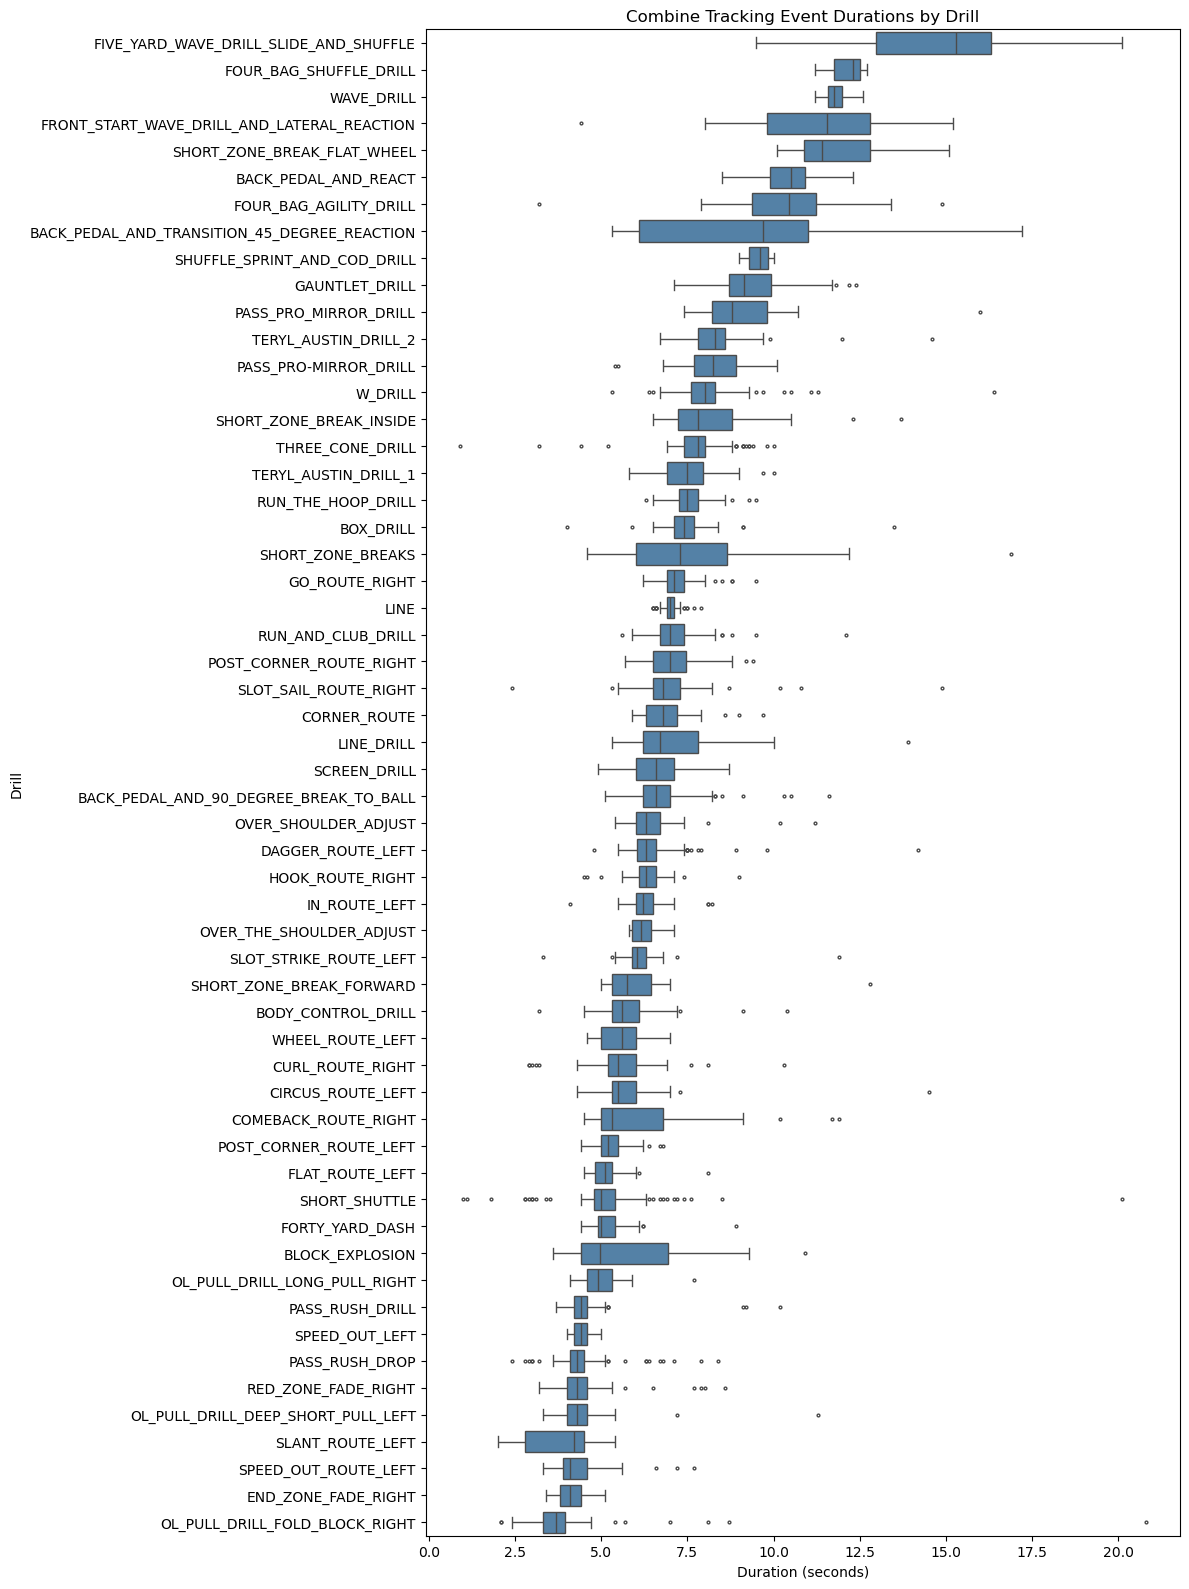

In [51]:
#Quick plot
plt.figure(figsize=(12, 16))

order = (
    event_durations.groupby("drill_name")["duration"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=event_durations,
    x="duration",
    y="drill_name",
    order=order,
    color="steelblue",
    fliersize=2
)

plt.title("Combine Tracking Event Durations by Drill")
plt.xlabel("Duration (seconds)")
plt.ylabel("Drill")
plt.tight_layout()
plt.show()

Some events are unusually long and some are unusually short

In [52]:
event_durations[
    (event_durations["duration"] < 2) |
    (event_durations["duration"] > 18)
][["event_id", "drill_name", "frames", "duration"]].sort_values("duration")

,event_id,drill_name,frames,duration
2149,20240303101000_1709502890626_000,THREE_CONE_DRILL,10,0.9
745,20240301100300_1709331900370_000,SHORT_SHUTTLE,11,1.0
3328,20250228100500_1740793859122_000,SHORT_SHUTTLE,12,1.1
4336,20250302101000_1740950071992_000,SHORT_SHUTTLE,19,1.8
1982,20240303101000_1709499766983_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,182,18.1
1972,20240303101000_1709499560263_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,185,18.4
1961,20240303101000_1709499343798_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,187,18.6
5100,6406869fe3d8e72dcdd1b95a-2023,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,187,18.6
1966,20240303101000_1709499445904_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,187,18.6
5269,64068a12e3d8e72dcddcb05e-2023,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,189,18.8


Some of these observations are troublesome. There are some three conde drills that end abruptly and must have some reasoning to support their inclusion. The drill may have been ended early or stopped via rules breaking. There is also some worriesome observations that went extremely long compared to the median drill times for short shuttle and OL pull/ fold block

### Moving on to the Games.csv


In [53]:
games = pd.read_csv(RAW_DATA_DIR / "games.csv")

print(games.shape)
games.info()

(1002, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   game_id            1002 non-null   int64 
 1   game_key           1002 non-null   int64 
 2   season             1002 non-null   int64 
 3   season_type        1002 non-null   object
 4   week               1002 non-null   int64 
 5   home_team_abbr     1002 non-null   object
 6   visitor_team_abbr  1002 non-null   object
dtypes: int64(4), object(3)
memory usage: 54.9+ KB


In [54]:
games.head()

,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


In [55]:
print(games["season"].value_counts().sort_index())
print(games["season_type"].value_counts())

print("Duplicate game IDs:", games["game_id"].duplicated().sum())
print("Duplicate game keys:", games["game_key"].duplicated().sum())

season
2023    334
2024    334
2025    334
Name: count, dtype: int64
season_type
REG     816
PRE     147
POST     39
Name: count, dtype: int64
Duplicate game IDs: 0
Duplicate game keys: 0


Dataset covers the three seasons for the players immediately following their respective drafts

In [56]:
pd.crosstab(games["season"], games["season_type"])

season_type,POST,PRE,REG
season,,,
2023,13,49,272
2024,13,49,272
2025,13,49,272


In [57]:
games.groupby(["season", "season_type", "week"]).size().unstack(
    ["season", "season_type"]
).fillna(0).astype(int)

season      2023         2024         2025        
season_type POST PRE REG POST PRE REG POST PRE REG
week                                              
0              0   1   0    0   1   0    0   1   0
1              0  16  16    0  16  16    0  16  16
2              0  16  16    0  16  16    0  16  16
3              0  16  16    0  16  16    0  16  16
4              0   0  16    0   0  16    0   0  16
5              0   0  14    0   0  14    0   0  14
6              0   0  15    0   0  14    0   0  15
7              0   0  13    0   0  15    0   0  15
8              0   0  16    0   0  16    0   0  13
9              0   0  14    0   0  15    0   0  14
10             0   0  14    0   0  14    0   0  14
11             0   0  14    0   0  14    0   0  15
12             0   0  16    0   0  13    0   0  14
13             0   0  13    0   0  16    0   0  16
14             0   0  15    0   0  13    0   0  14
15             0   0  16    0   0  16    0   0  16
16             0   0  16    0   0  16    0   0  16
17             0   0  16    0   0  16    0   0  16
18             0   0  16    0   0  16    0   0  16
19             6   0   0    6   0   0    6   0   0
20             4   0   0    4   0   0    4   0   0
21             2   0   0    2   0   0    2   0   0
23             1   0   0    1   0   0    1   0   0

In [58]:
#verify team identifiers
teams = set(games["home_team_abbr"]) | set(games["visitor_team_abbr"])

print("Unique teams:", len(teams))
print("Teams:", sorted(teams))
print("Same home and away team:",
      (games["home_team_abbr"] == games["visitor_team_abbr"]).sum())

Unique teams: 33
Teams: ['ARI', 'ATL', 'BAL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'DAL', 'DEN', 'DET', 'GB', 'HOU', 'IND', 'JAX', 'KC', 'LA', 'LAC', 'LAR', 'LV', 'MIA', 'MIN', 'NE', 'NO', 'NYG', 'NYJ', 'PHI', 'PIT', 'SEA', 'SF', 'TB', 'TEN', 'WAS']
Same home and away team: 0


La and LAR both refer to the LA Rams and must be fixed

In [59]:
games[
    games["home_team_abbr"].isin(["LA", "LAR"]) |
    games["visitor_team_abbr"].isin(["LA", "LAR"])
].groupby(
    ["season", "season_type", "home_team_abbr", "visitor_team_abbr"]
).size()

season  season_type  home_team_abbr  visitor_team_abbr
2023    POST         DET             LA                   1
        PRE          DEN             LA                   1
                     LA              LAC                  1
                                     LV                   1
        REG          ARI             LA                   1
                                                         ..
2025    REG          LAR             TB                   1
                     PHI             LAR                  1
                     SEA             LAR                  1
                     SF              LAR                  1
                     TEN             LAR                  1
Length: 66, dtype: int64

In [60]:
for season in sorted(games["season"].unique()):
    subset = games[games["season"] == season]
    print(f"\nSeason {season}")
    print("LA:", subset[["home_team_abbr", "visitor_team_abbr"]].eq("LA").sum().sum())
    print("LAR:", subset[["home_team_abbr", "visitor_team_abbr"]].eq("LAR").sum().sum())


Season 2023
LA: 21
LAR: 0

Season 2024
LA: 22
LAR: 0

Season 2025
LA: 0
LAR: 23


This inconsitency is attributed to the Rams moving to LAR in 2025

### Judgment call
We should standardize LA to LAR

In [61]:
games_clean = games.copy()

games_clean["home_team_abbr"] = games_clean["home_team_abbr"].replace("LA", "LAR")
games_clean["visitor_team_abbr"] = games_clean["visitor_team_abbr"].replace("LA", "LAR")

teams_clean = set(games_clean["home_team_abbr"]) | set(games_clean["visitor_team_abbr"])

print("Unique teams:", len(teams_clean))
print("Duplicate game IDs:", games_clean["game_id"].duplicated().sum())
print("Same home and away team:",
      (games_clean["home_team_abbr"] == games_clean["visitor_team_abbr"]).sum())

Unique teams: 32
Duplicate game IDs: 0
Same home and away team: 0


### Moving on to Game tracking 2023


In [62]:
game_tracking_2023 = pd.read_csv(
    RAW_DATA_DIR / "game_tracking_2023.csv"
)

print("Shape:", game_tracking_2023.shape)
print("\nColumn information:")
game_tracking_2023.info()

display(game_tracking_2023.head())

Shape: (3665443, 12)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3665443 entries, 0 to 3665442
Data columns (total 12 columns):
 #   Column   Dtype  
---  ------   -----  
 0   game_id  int64  
 1   play_id  int64  
 2   nfl_id   int64  
 3   time     object 
 4   x        float64
 5   y        float64
 6   s        float64
 7   a        float64
 8   dis      float64
 9   o        float64
 10  dir      float64
 11  event    object 
dtypes: float64(7), int64(3), object(2)
memory usage: 335.6+ MB


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2024010707,570,56450,2024-01-07T21:46:07.700,42.17,25.29,0.0,0.0,0.0,290.97,213.26,NaN
1,2024010707,570,56450,2024-01-07T21:46:07.800,42.17,25.29,0.0,0.0,0.0,290.97,210.36,NaN
2,2024010707,570,56450,2024-01-07T21:46:07.900,42.18,25.29,0.0,0.0,0.0,290.97,205.45,NaN
3,2024010707,570,56450,2024-01-07T21:46:08.000,42.18,25.29,0.0,0.0,0.0,290.97,200.73,NaN
4,2024010707,570,56450,2024-01-07T21:46:08.100,42.18,25.29,0.0,0.0,0.0,290.97,199.27,NaN


Very large data set with approx 3.66 million observations

In [63]:
#Check for missing values and coverage
print("Unique games:", game_tracking_2023["game_id"].nunique())
print("Unique plays:", game_tracking_2023[["game_id", "play_id"]].drop_duplicates().shape[0])
print("Unique players:", game_tracking_2023["nfl_id"].nunique())

print("\nMissing values:")
display(game_tracking_2023.isna().sum())

print("\nExact duplicate rows:", game_tracking_2023.duplicated().sum())

Unique games: 333
Unique plays: 31690
Unique players: 156

Missing values:


game_id          0
play_id          0
nfl_id           0
time             0
x                0
y                0
s                0
a                0
dis              0
o                0
dir              0
event      3422066
dtype: int64


Exact duplicate rows: 0


This dataset tracks a small subset of NFL players (156), only those present in the 2023 NFL Draft

In [64]:
#Game coverage and player distribution
games_2023 = set(games.loc[games["season"] == 2023, "game_id"])
tracked_games = set(game_tracking_2023["game_id"])

print("Games without tracking:", games_2023 - tracked_games)
print("Tracked games not in games.csv:", tracked_games - games_2023)

print("\nTracking observations per player:")
display(
    game_tracking_2023.groupby("nfl_id")
    .size()
    .describe()
)

Games without tracking: {2023100108}
Tracked games not in games.csv: set()

Tracking observations per player:


count      156.000000
mean     23496.429487
std      22911.160245
min        115.000000
25%       6431.000000
50%      14437.500000
75%      36744.000000
max      98097.000000
dtype: float64

Not all players play equal amounts once they are in the professionals


In [65]:
#check overlap with combine data
tracked_players = set(game_tracking_2023["nfl_id"])
combine_players = set(combine["nfl_id"])

print("Tracked players:", len(tracked_players))
print("Combine players:", len(combine_players))
print("Players in both:", len(tracked_players & combine_players))
print("Tracking-only players:", len(tracked_players - combine_players))
print("Combine-only players:", len(combine_players - tracked_players))

Tracked players: 156
Combine players: 510
Players in both: 156
Tracking-only players: 0
Combine-only players: 354


In [66]:
tracked_2023 = combine[
    combine["nfl_id"].isin(game_tracking_2023["nfl_id"])
]

pd.crosstab(
    combine["draft_year"],
    combine["nfl_id"].isin(game_tracking_2023["nfl_id"]),
    rownames=["Draft year"],
    colnames=["Tracked in 2023"]
)

Tracked in 2023,False,True
Draft year,,
2023,4,156
2024,177,0
2025,173,0


In [67]:
print("Unique event types:", game_tracking_2023["event"].nunique())

display(
    game_tracking_2023["event"]
    .value_counts(dropna=False)
)

Unique event types: 44


event
NaN                          3422066
ball_snap                      50813
pass_forward                   31422
tackle                         29011
first_contact                  28345
pass_arrived                   23967
pass_outcome_caught            18845
handoff                        14053
pass_outcome_incomplete        10862
play_action                     8274
out_of_bounds                   6082
autoevent_passinterrupted       4237
run                             2899
qb_sack                         2104
man_in_motion                   1827
line_set                        1610
play_submit                     1264
touchdown                       1174
dropped_pass                     807
pass_outcome_interception        754
pass_outcome_touchdown           646
pass_tipped                      561
fumble                           496
qb_kneel                         493
qb_slide                         419
shift                            397
fumble_offense_recovered        

In [68]:
#Check tracking observation uniqueness
print(
    "Duplicate player-play-timestamp records:",
    game_tracking_2023.duplicated(
        subset=["game_id", "play_id", "nfl_id", "time"]
    ).sum()
)

print("\nMissing values by column:")
display(game_tracking_2023.isna().sum())

print("\nUnique timestamps:", game_tracking_2023["time"].nunique())

Duplicate player-play-timestamp records: 0

Missing values by column:


game_id          0
play_id          0
nfl_id           0
time             0
x                0
y                0
s                0
a                0
dis              0
o                0
dir              0
event      3422066
dtype: int64


Unique timestamps: 2032176


In [69]:
#Tracking frequency
game_tracking_2023["time"] = pd.to_datetime(game_tracking_2023["time"])

tracking_sorted_2023 = game_tracking_2023.sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
)

dt = (
    tracking_sorted_2023
    .groupby(["game_id", "play_id", "nfl_id"])["time"]
    .diff()
    .dt.total_seconds()
)

print("Sampling interval distribution:")
display(dt.value_counts(dropna=False).head(15))

print("\nSampling interval summary:")
display(dt.describe())

Sampling interval distribution:


time
0.1    3614529
NaN      50911
0.2          3
Name: count, dtype: int64


Sampling interval summary:


count    3.614532e+06
mean     1.000001e-01
std      9.110338e-05
min      1.000000e-01
25%      1.000000e-01
50%      1.000000e-01
75%      1.000000e-01
max      2.000000e-01
Name: time, dtype: float64

Just like the combine tracking data the frequency tracking data here is measured at 10hz

In [70]:
tracking_cols = ["x", "y", "s", "a", "dis", "o", "dir"]

game_tracking_2023[tracking_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
x,3665443.0,60.178,24.514,-5.89,40.98,60.29,79.34,126.73
y,3665443.0,26.793,9.697,-7.29,21.04,26.77,32.49,61.24
s,3665443.0,2.531,2.127,0.00,0.81,2.08,3.79,12.67
a,3665443.0,1.636,1.294,0.00,0.65,1.40,2.35,18.33
dis,3665443.0,0.257,0.214,0.00,0.08,0.21,0.38,3.44
o,3665443.0,177.684,100.822,0.00,88.21,177.50,268.08,360.00
dir,3665443.0,179.621,103.362,0.00,89.01,179.83,269.41,360.00


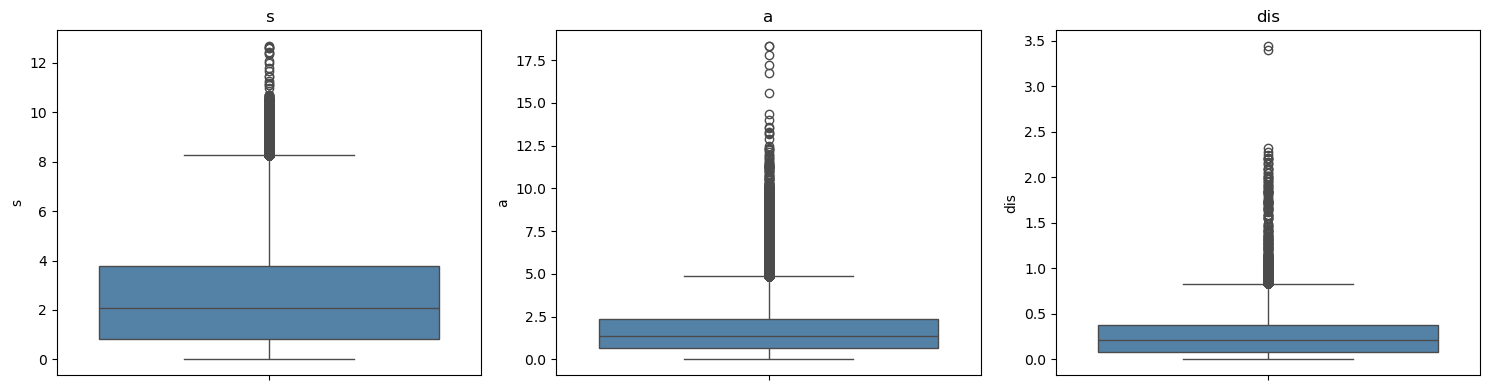

In [71]:
#Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["s", "a", "dis"]):
    sns.boxplot(
        y=game_tracking_2023[col],
        ax=ax,
        color="steelblue"
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [73]:
#Check the observations outside the field
outside_field = (
    (game_tracking_2023["x"] < 0) |
    (game_tracking_2023["x"] > 120) |
    (game_tracking_2023["y"] < 0) |
    (game_tracking_2023["y"] > 53.3)
)

print("Observations outside field:", outside_field.sum())
print("Percentage outside field:", round(outside_field.mean() * 100, 3))

Observations outside field: 14336
Percentage outside field: 0.391


Only a tiny portion of measurements are from outside the playing field which can be attributed to the sensor out of bounds.

In [74]:
tracking_sorted_2023 = game_tracking_2023.sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
).copy()

groups = tracking_sorted_2023.groupby(
    ["game_id", "play_id", "nfl_id"]
)

tracking_sorted_2023["calculated_dis"] = np.sqrt(
    groups["x"].diff()**2 +
    groups["y"].diff()**2
)

dis_comparison = tracking_sorted_2023[
    ["dis", "calculated_dis"]
].dropna().copy()

dis_comparison["absolute_error"] = (
    dis_comparison["dis"] - dis_comparison["calculated_dis"]
).abs()

print("Correlation:", dis_comparison["dis"].corr(dis_comparison["calculated_dis"]))
print("Mean absolute error:", dis_comparison["absolute_error"].mean())
print("95th percentile error:", dis_comparison["absolute_error"].quantile(0.95))

display(dis_comparison.nlargest(10, "absolute_error"))

Correlation: 0.9746138299852448
Mean absolute error: 0.0038421134005024284
95th percentile error: 0.010000000000001563


,dis,calculated_dis,absolute_error
2531452,0.00,40.576566,40.576566
2530320,0.00,39.660944,39.660944
2531486,0.00,39.031302,39.031302
2530364,0.01,38.726411,38.716411
927701,0.00,34.074725,34.074725
927740,0.01,33.590862,33.580862
165841,0.29,1.290620,1.000620
2032482,0.37,1.222865,0.852865
1424536,0.17,0.940851,0.770851
2339605,0.93,0.172627,0.757373


In [75]:
#Six obersvations draw a closer look
tracking_sorted_2023["dis_error"] = (
    tracking_sorted_2023["dis"] -
    tracking_sorted_2023["calculated_dis"]
).abs()

display(
    tracking_sorted_2023.nlargest(10, "dis_error")[
        ["game_id", "play_id", "nfl_id", "time",
         "x", "y", "s", "dis", "calculated_dis", "dis_error"]
    ]
)

,game_id,play_id,nfl_id,time,x,y,s,dis,calculated_dis,dis_error
2531452,2023081151,115,55922,2023-08-11 23:10:44.500,41.38,24.20,0.00,0.00,40.576566,40.576566
2530320,2023081151,93,55922,2023-08-11 23:10:19.900,43.33,24.25,0.00,0.00,39.660944,39.660944
2531486,2023081151,115,55922,2023-08-11 23:10:48.000,63.68,58.02,0.01,0.00,39.031302,39.031302
2530364,2023081151,93,55922,2023-08-11 23:10:24.400,64.10,58.03,0.09,0.01,38.726411,38.716411
927701,2023081151,1836,55922,2023-08-12 00:17:08.000,96.00,30.33,0.00,0.00,34.074725,34.074725
927740,2023081151,1836,55922,2023-08-12 00:17:12.000,77.86,59.03,0.03,0.01,33.590862,33.580862
165841,2023081151,332,55922,2023-08-11 23:19:12.500,32.33,22.29,3.56,0.29,1.290620,1.000620
2032482,2023091708,3978,55888,2023-09-17 22:54:47.800,83.36,12.92,3.56,0.37,1.222865,0.852865
1424536,2023081151,948,55922,2023-08-11 23:42:27.900,83.04,23.93,6.34,0.17,0.940851,0.770851
2339605,2023081151,1649,55922,2023-08-12 00:10:00.700,56.00,24.62,0.17,0.93,0.172627,0.757373


In [76]:
#Anomaly spread
anomalies = tracking_sorted_2023[
    tracking_sorted_2023["dis_error"] > 0.5
]

print("Anomalous observations:", len(anomalies))
print("Percentage of valid comparisons:",
      round(len(anomalies) / len(dis_comparison) * 100, 4))

print("Affected players:", anomalies["nfl_id"].nunique())
print("Affected games:", anomalies["game_id"].nunique())
print("Affected plays:",
      anomalies[["game_id", "play_id"]].drop_duplicates().shape[0])

display(
    anomalies.groupby(["game_id", "nfl_id"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Anomalous observations: 14
Percentage of valid comparisons: 0.0004
Affected players: 2
Affected games: 2
Affected plays: 9


game_id     nfl_id
2023081151  55922     13
2023091708  55888      1
dtype: int64

In [77]:
#Check if there is direct connection between cordinate speed and recorded speed
tracking_sorted_2023["dt"] = (
    tracking_sorted_2023.groupby(
        ["game_id", "play_id", "nfl_id"]
    )["time"].diff().dt.total_seconds()
)

tracking_sorted_2023["calculated_speed"] = (
    tracking_sorted_2023["calculated_dis"] /
    tracking_sorted_2023["dt"]
)

speed_comparison = tracking_sorted_2023[
    ["s", "calculated_speed"]
].replace([np.inf, -np.inf], np.nan).dropna().copy()

speed_comparison["absolute_error"] = (
    speed_comparison["s"] - speed_comparison["calculated_speed"]
).abs()

print("Correlation:", speed_comparison["s"].corr(speed_comparison["calculated_speed"]))
print("Mean absolute error:", speed_comparison["absolute_error"].mean())
print("Median absolute error:", speed_comparison["absolute_error"].median())
print("95th percentile error:", speed_comparison["absolute_error"].quantile(0.95))


Correlation: 0.9812123260457997
Mean absolute error: 0.0922079127691224
Median absolute error: 0.07099202643648539
95th percentile error: 0.23960780543714022


In [78]:
valid_speed = tracking_sorted_2023[
    tracking_sorted_2023["calculated_speed"].notna()
]

clean_speed = valid_speed[
    valid_speed["dis_error"] <= 0.5
]

print("All observations correlation:",
      valid_speed["s"].corr(valid_speed["calculated_speed"]))

print("Without flagged intervals correlation:",
      clean_speed["s"].corr(clean_speed["calculated_speed"]))

print("Without flagged intervals MAE:",
      (clean_speed["s"] - clean_speed["calculated_speed"]).abs().mean())

All observations correlation: 0.9812123260457997
Without flagged intervals correlation: 0.9973232845172773
Without flagged intervals MAE: 0.0917287628688532


The fourteen observations that once removed increase the correlation from 0.9812 to 0.9973


In [79]:
#Check player coverage
player_coverage_2023 = (
    game_tracking_2023.groupby("nfl_id")
    .agg(
        games=("game_id", "nunique"),
        tracking_frames=("time", "size")
    )
)

player_coverage_2023["plays"] = (
    game_tracking_2023.groupby("nfl_id")
    .apply(
        lambda x: x[["game_id", "play_id"]].drop_duplicates().shape[0],
        include_groups=False
    )
)

display(player_coverage_2023.describe().round(2))

,games,tracking_frames,plays
count,156.00,156.00,156.00
mean,11.38,23496.43,326.35
std,6.81,22911.16,321.66
min,1.00,115.00,1.00
25%,4.00,6431.00,91.00
50%,12.00,14437.50,200.50
75%,18.00,36744.00,511.75
max,24.00,98097.00,1383.00


In [80]:
#Player coverage by position
players = pd.read_csv(RAW_DATA_DIR / "players.csv")

coverage_by_position_2023 = player_coverage_2023.reset_index().merge(
    players[["nfl_id", "nfl_position"]],
    on="nfl_id",
    how="left",
    validate="one_to_one"
)

print("Players without position:",
      coverage_by_position_2023["nfl_position"].isna().sum())

display(
    coverage_by_position_2023.groupby("nfl_position")[
        ["games", "plays", "tracking_frames"]
    ].agg(["count", "median", "mean"]).round(1)
)

Players without position: 0


games              plays               tracking_frames           \
             count median  mean count median   mean           count   median   
nfl_position                                                                   
C                7    6.0   6.4     7  172.0  301.4               7  12368.0   
CB              15   10.0   9.9    15  340.0  378.7              15  24925.0   
DE              14   10.5  11.6    14  207.0  266.9              14  14598.5   
DT               8   10.5  11.5     8  215.0  266.5               8  15129.5   
FS               7    4.0   6.9     7  110.0  187.3               7   7841.0   
G               17   12.0  11.5    17  471.0  563.4              17  32020.0   
NT               3    8.0  10.0     3  173.0  166.0               3  12364.0   
OLB             10   15.0  13.2    10  214.5  375.0              10  15570.5   
SS              12   11.5  11.8    12  231.0  347.7              12  16419.0   
T               13    8.0  10.2    13  228.0  527.2              13  15545.0   
TE              12   14.0  12.7    12  110.0  130.6              12   8357.0   
WR              38   16.0  13.1    38  229.0  250.6              38  17500.0   

                       
                 mean  
nfl_position           
C             21541.3  
CB            26998.3  
DE            18827.7  
DT            18941.6  
FS            13496.0  
G             39593.4  
NT            11865.7  
OLB           26611.5  
SS            25010.8  
T             37543.1  
TE             9812.0  
WR            18930.3

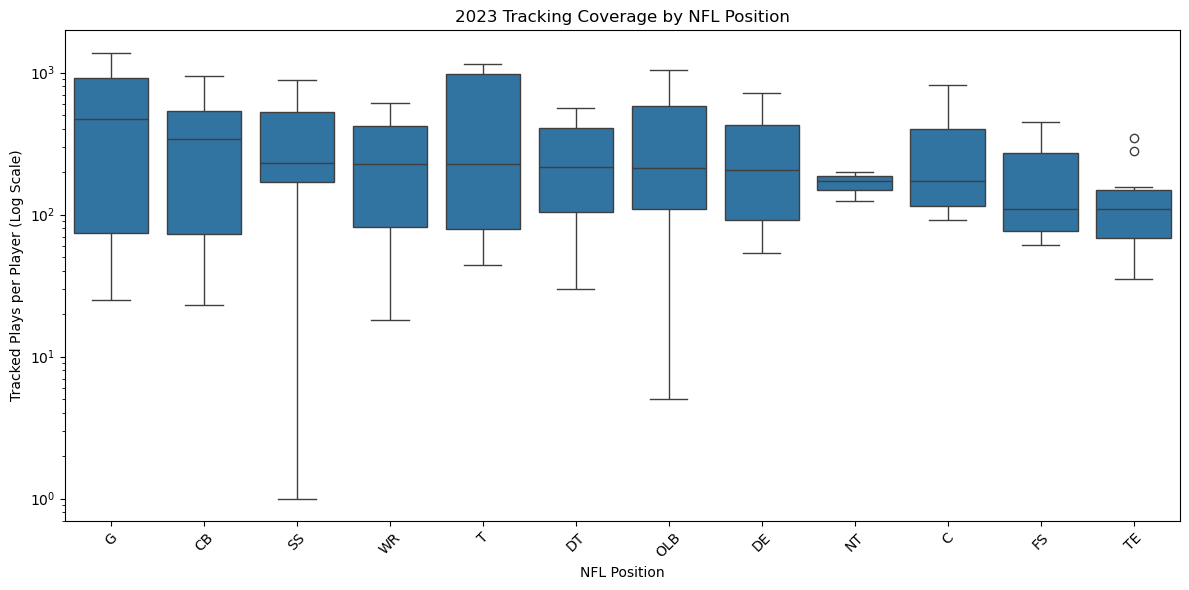

In [81]:
#Quick plot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=coverage_by_position_2023,
    x="nfl_position",
    y="plays",
    order=coverage_by_position_2023.groupby("nfl_position")["plays"].median().sort_values(ascending=False).index
)

plt.yscale("log")
plt.title("2023 Tracking Coverage by NFL Position")
plt.xlabel("NFL Position")
plt.ylabel("Tracked Plays per Player (Log Scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### We can move on to the 2024 season tracking data


In [82]:
import time

start = time.time()

game_tracking_2024 = pd.read_csv(
    RAW_DATA_DIR / "game_tracking_2024.csv"
)

print("Shape:", game_tracking_2024.shape)
print("Memory (MB):", round(game_tracking_2024.memory_usage(deep=True).sum() / 1e6, 2))
print("Load time (seconds):", round(time.time() - start, 2))

display(game_tracking_2024.head())
display(game_tracking_2024.dtypes)

Shape: (7827944, 12)
Memory (MB): 1455.25
Load time (seconds): 13.47


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2024080952,3379,57367,2024-08-10T01:30:31.800,87.09,22.52,0.28,0.11,0.03,98.51,126.08,NaN
1,2024080952,3379,57367,2024-08-10T01:30:31.900,87.11,22.51,0.24,0.18,0.02,97.33,125.81,NaN
2,2024080952,3379,57367,2024-08-10T01:30:32.000,87.12,22.50,0.17,0.24,0.01,96.65,124.99,NaN
3,2024080952,3379,57367,2024-08-10T01:30:32.100,87.13,22.49,0.15,0.21,0.02,95.42,120.75,NaN
4,2024080952,3379,57367,2024-08-10T01:30:32.200,87.14,22.48,0.11,0.19,0.01,95.42,136.32,NaN


game_id      int64
play_id      int64
nfl_id       int64
time        object
x          float64
y          float64
s          float64
a          float64
dis        float64
o          float64
dir        float64
event       object
dtype: object

In [83]:
print("Missing values:")
display(game_tracking_2024.isna().sum())

print("Exact duplicates:", game_tracking_2024.duplicated().sum())

print("Duplicate tracking keys:",
      game_tracking_2024.duplicated(
          ["game_id", "play_id", "nfl_id", "time"]
      ).sum())

print("Unique games:", game_tracking_2024["game_id"].nunique())

print("Unique plays:",
      game_tracking_2024[["game_id", "play_id"]].drop_duplicates().shape[0])

print("Unique players:", game_tracking_2024["nfl_id"].nunique())

Missing values:


game_id          0
play_id          0
nfl_id           0
time             0
x                0
y                0
s                0
a                0
dis              0
o                0
dir              0
event      7306249
dtype: int64

Exact duplicates: 0
Duplicate tracking keys: 0
Unique games: 334
Unique plays: 40331
Unique players: 318


Important note! The players from the 2023 season are also in the 2024 tracking dataset essentially doubling the observations for those players. We can check draft year distriubtion


In [84]:
players_2024 = (
    game_tracking_2024[["nfl_id"]]
    .drop_duplicates()
    .merge(
        players[["nfl_id", "draft_year", "nfl_position"]],
        on="nfl_id",
        how="left",
        validate="one_to_one"
    )
)

print("Draft year distribution:")
display(players_2024["draft_year"].value_counts(dropna=False).sort_index())

print("Players without metadata:", players_2024["draft_year"].isna().sum())

print("Position distribution:")
display(players_2024["nfl_position"].value_counts(dropna=False))


Draft year distribution:


draft_year
2023    146
2024    172
Name: count, dtype: int64

Players without metadata: 0
Position distribution:


nfl_position
WR     65
CB     42
T      32
G      31
TE     25
DT     24
DE     24
SS     19
OLB    17
C      16
FS     15
NT      4
ILB     1
MLB     1
RB      1
DB      1
Name: count, dtype: int64

In [85]:
#Checking player coverage
ids_2023 = set(game_tracking_2023["nfl_id"].unique())
ids_2024 = set(game_tracking_2024["nfl_id"].unique())

print("Players in both seasons:", len(ids_2023 & ids_2024))
print("2023 players absent in 2024:", len(ids_2023 - ids_2024))
print("New players in 2024:", len(ids_2024 - ids_2023))

print("\nTracking observations per player:")
display(
    game_tracking_2024.groupby("nfl_id")
    .size()
    .describe()
)

Players in both seasons: 145
2023 players absent in 2024: 11
New players in 2024: 173

Tracking observations per player:


count      318.000000
mean     24616.176101
std      23574.594561
min         94.000000
25%       6723.500000
50%      15447.500000
75%      37782.000000
max      88790.000000
dtype: float64

In [86]:
tracking_cols = ["x", "y", "s", "a", "dis", "o", "dir"]

display(
    game_tracking_2024[tracking_cols]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
    .round(3)
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
x,7827944.0,59.664,24.428,-6.33,9.86,18.93,41.37,59.54,78.00,100.54,109.88,125.66
y,7827944.0,26.774,9.612,-8.13,3.53,9.99,20.97,26.79,32.59,43.58,49.94,63.96
s,7827944.0,2.518,2.075,0.00,0.00,0.01,0.83,2.09,3.76,6.65,8.20,13.87
a,7827944.0,1.590,1.221,0.00,0.00,0.02,0.65,1.37,2.28,3.94,5.22,22.02
dis,7827944.0,0.256,0.209,0.00,0.00,0.00,0.08,0.21,0.38,0.67,0.82,16.86
o,7827944.0,178.882,100.639,0.00,4.66,23.70,89.25,179.97,268.71,334.69,355.25,360.00
dir,7827944.0,180.110,103.309,0.00,3.45,18.18,90.12,179.99,269.58,342.11,356.55,360.00


In [87]:
#Quantify suspicous observations
checks_2024 = {
    "x outside [0, 120]": ((game_tracking_2024["x"] < 0) | (game_tracking_2024["x"] > 120)),
    "y outside [0, 53.33]": ((game_tracking_2024["y"] < 0) | (game_tracking_2024["y"] > 53.33)),
    "speed > 10 yd/s": game_tracking_2024["s"] > 10,
    "acceleration > 10 yd/s²": game_tracking_2024["a"] > 10,
    "distance > 1 yd/frame": game_tracking_2024["dis"] > 1,
    "orientation outside [0, 360]": ~game_tracking_2024["o"].between(0, 360),
    "direction outside [0, 360]": ~game_tracking_2024["dir"].between(0, 360)
}

audit_2024 = pd.DataFrame({
    "count": {name: mask.sum() for name, mask in checks_2024.items()},
    "percentage": {name: 100 * mask.mean() for name, mask in checks_2024.items()}
})

display(audit_2024.round(5))

,count,percentage
"x outside [0, 120]",1689,0.02158
"y outside [0, 53.33]",28283,0.36131
speed > 10 yd/s,1127,0.01440
acceleration > 10 yd/s²,94,0.00120
distance > 1 yd/frame,1527,0.01951
"orientation outside [0, 360]",0,0.00000
"direction outside [0, 360]",0,0.00000


In [88]:
distance_anomalies_2024 = game_tracking_2024.loc[
    game_tracking_2024["dis"] > 1
].copy()

print("Affected players:", distance_anomalies_2024["nfl_id"].nunique())
print("Affected games:", distance_anomalies_2024["game_id"].nunique())
print("Affected plays:",
      distance_anomalies_2024[["game_id", "play_id"]].drop_duplicates().shape[0])

print("\nTop 10 players by anomaly count:")
display(
    distance_anomalies_2024["nfl_id"]
    .value_counts()
    .head(10)
)

print("\nLargest distance observations:")
display(
    distance_anomalies_2024.nlargest(10, "dis")[
        ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "a", "dis", "event"]
    ]
)

Affected players: 133
Affected games: 207
Affected plays: 389

Top 10 players by anomaly count:


nfl_id
57144    143
57267     89
55928     81
57140     63
57257     49
57173     47
57199     46
55965     42
56056     37
57234     36
Name: count, dtype: int64


Largest distance observations:


,game_id,play_id,nfl_id,time,x,y,s,a,dis,event
1599562,2024101300,243,57144,2024-10-13T13:36:29.200,81.41,4.78,2.40,2.17,16.86,NaN
504860,2024101302,442,55943,2024-10-13T17:18:49.500,13.93,10.68,1.72,1.61,5.03,NaN
2880641,2024111100,2953,57304,2024-11-12T03:25:21.000,70.65,39.37,7.00,4.68,4.45,pass_forward
1758202,2024101300,243,55891,2024-10-13T13:36:29.200,92.59,22.74,2.18,0.47,4.36,NaN
3278492,2024102006,3650,57145,2024-10-20T19:47:21.200,7.41,20.02,13.87,22.02,3.57,NaN
2880643,2024111100,2953,57304,2024-11-12T03:25:21.200,72.27,41.77,7.31,2.34,2.89,NaN
5995510,2024110310,2445,57179,2024-11-03T23:20:12.500,24.28,35.62,0.37,1.16,2.55,NaN
7382835,2024080951,3747,57156,2024-08-10T01:52:49.700,60.53,23.34,4.23,1.53,2.49,NaN
2456545,2024080951,3722,57156,2024-08-10T01:52:08.500,51.92,12.96,0.08,0.26,2.45,NaN
7374291,2024102101,3039,57164,2024-10-22T03:09:13.700,21.07,55.48,7.01,1.98,2.31,NaN


In [89]:
player_sequence = game_tracking_2024.loc[
    (game_tracking_2024["game_id"] == 2024101300) &
    (game_tracking_2024["play_id"] == 243) &
    (game_tracking_2024["nfl_id"] == 57144)
].copy()

player_sequence["time"] = pd.to_datetime(player_sequence["time"])

player_sequence = player_sequence.sort_values("time")

display(
    player_sequence.loc[
        player_sequence["dis"] > 1,
        ["time", "x", "y", "s", "a", "dis"]
    ]
)

display(
    player_sequence[
        ["time", "x", "y", "s", "a", "dis"]
    ].head(20)
)

,time,x,y,s,a,dis
1599562,2024-10-13 13:36:29.200,81.41,4.78,2.4,2.17,16.86


,time,x,y,s,a,dis
1599507,2024-10-13 13:36:23.700,90.33,15.90,0.00,0.00,0.00
1599508,2024-10-13 13:36:23.800,90.33,15.90,0.00,0.00,0.00
1599509,2024-10-13 13:36:23.900,90.33,15.90,0.00,0.00,0.00
1599510,2024-10-13 13:36:24.000,90.33,15.90,0.00,0.00,0.00
1599511,2024-10-13 13:36:24.100,90.33,15.90,0.00,0.00,0.00
1599512,2024-10-13 13:36:24.200,90.33,15.90,0.00,0.14,0.00
1599513,2024-10-13 13:36:24.300,90.33,15.90,0.03,0.30,0.00
1599514,2024-10-13 13:36:24.400,90.33,15.90,0.14,0.83,0.00
1599515,2024-10-13 13:36:24.500,90.30,15.90,0.35,1.45,0.03
1599516,2024-10-13 13:36:24.600,90.23,15.90,0.57,1.82,0.07


In [90]:
#Cordiate jumps
anomaly_time = pd.Timestamp("2024-10-13 13:36:29.200")

display(
    player_sequence.loc[
        player_sequence["time"].between(
            anomaly_time - pd.Timedelta(seconds=1),
            anomaly_time + pd.Timedelta(seconds=1)
        ),
        ["time", "x", "y", "s", "a", "dis"]
    ]
)

,time,x,y,s,a,dis
1599552,2024-10-13 13:36:28.200,82.93,6.30,1.76,2.26,0.17
1599553,2024-10-13 13:36:28.300,82.73,6.30,1.96,1.66,0.20
1599554,2024-10-13 13:36:28.400,82.53,6.23,2.19,1.54,0.21
1599555,2024-10-13 13:36:28.500,82.33,6.10,2.33,2.09,0.24
1599556,2024-10-13 13:36:28.600,82.17,5.97,2.36,2.04,0.21
1599557,2024-10-13 13:36:28.700,81.97,5.83,2.47,2.14,0.24
1599558,2024-10-13 13:36:28.800,81.80,5.63,2.57,2.02,0.26
1599559,2024-10-13 13:36:28.900,81.63,5.43,2.63,1.77,0.26
1599560,2024-10-13 13:36:29.000,81.57,5.23,2.48,2.35,0.21
1599561,2024-10-13 13:36:29.100,81.47,5.00,2.45,2.29,0.25


The Dis column is incorrectly behaving, and may need further attention before we blindy inlcude this predictor.

In [91]:
#Validate the Dis cordinate vs calculated distance
tracking_2024_sorted = game_tracking_2024.sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
).copy()

groups = tracking_2024_sorted.groupby(
    ["game_id", "play_id", "nfl_id"]
)

dx = groups["x"].diff()
dy = groups["y"].diff()

tracking_2024_sorted["calculated_dis"] = np.sqrt(dx**2 + dy**2)

tracking_2024_sorted["dt"] = (
    pd.to_datetime(tracking_2024_sorted["time"])
    .groupby([
        tracking_2024_sorted["game_id"],
        tracking_2024_sorted["play_id"],
        tracking_2024_sorted["nfl_id"]
    ])
    .diff()
    .dt.total_seconds()
)

valid_2024 = tracking_2024_sorted["dt"].between(0.099, 0.101)

tracking_2024_sorted["dis_error"] = (
    tracking_2024_sorted["dis"] -
    tracking_2024_sorted["calculated_dis"]
)

print("Valid consecutive frames:", valid_2024.sum())

print("Mean absolute distance error:",
      tracking_2024_sorted.loc[valid_2024, "dis_error"].abs().mean())

print("Distance errors > 0.5 yards:",
      (tracking_2024_sorted.loc[valid_2024, "dis_error"].abs() > 0.5).sum())

print("Distance errors > 1 yard:",
      (tracking_2024_sorted.loc[valid_2024, "dis_error"].abs() > 1).sum())

print("Correlation:",
      tracking_2024_sorted.loc[
          valid_2024, ["dis", "calculated_dis"]
      ].corr().iloc[0, 1])

Valid consecutive frames: 7719221
Mean absolute distance error: 0.003798315045527619
Distance errors > 0.5 yards: 3
Distance errors > 1 yard: 3
Correlation: 0.9992707584386119


# Three mismatches

In [92]:
large_errors_2024 = tracking_2024_sorted.loc[
    valid_2024 &
    (tracking_2024_sorted["dis_error"].abs() > 0.5)
]

display(
    large_errors_2024[
        [
            "game_id", "play_id", "nfl_id", "time",
            "x", "y", "s", "a", "dis",
            "calculated_dis", "dis_error"
        ]
    ]
)

,game_id,play_id,nfl_id,time,x,y,s,a,dis,calculated_dis,dis_error
1571444,2024081059,4061,56625,2024-08-11T02:55:43.500,88.87,27.23,2.29,1.79,1.03,0.000000,1.030000
1758202,2024101300,243,55891,2024-10-13T13:36:29.200,92.59,22.74,2.18,0.47,4.36,0.218403,4.141597
1599562,2024101300,243,57144,2024-10-13T13:36:29.200,81.41,4.78,2.40,2.17,16.86,0.228035,16.631965


We must determine if these instances are real recordings or are physically impossible and should be omitted completely


In [93]:
tracking_2024_sorted["calculated_speed"] = (
    tracking_2024_sorted["calculated_dis"] /
    tracking_2024_sorted["dt"]
)

speed_check_2024 = tracking_2024_sorted.loc[
    valid_2024,
    ["s", "calculated_speed"]
].copy()

speed_check_2024["speed_error"] = (
    speed_check_2024["calculated_speed"] -
    speed_check_2024["s"]
)

print("Speed correlation:",
      speed_check_2024[["s", "calculated_speed"]].corr().iloc[0, 1])

print("Mean absolute speed error:",
      speed_check_2024["speed_error"].abs().mean())

print("Speed errors > 5 yd/s:",
      (speed_check_2024["speed_error"].abs() > 5).sum())

print("Calculated speeds > 12 yd/s:",
      (speed_check_2024["calculated_speed"] > 12).sum())

print("\nLargest calculated speeds:")
display(
    tracking_2024_sorted.loc[valid_2024]
    .nlargest(10, "calculated_speed")[
        [
            "game_id", "play_id", "nfl_id", "time",
            "s", "calculated_speed", "dis", "calculated_dis"
        ]
    ]
)

Speed correlation: 0.9972492933685908
Mean absolute speed error: 0.09443874293149508
Speed errors > 5 yd/s: 504
Calculated speeds > 12 yd/s: 233

Largest calculated speeds:


,game_id,play_id,nfl_id,time,s,calculated_speed,dis,calculated_dis
504860,2024101302,442,55943,2024-10-13T17:18:49.500,1.72,50.330210,5.03,5.033021
2880641,2024111100,2953,57304,2024-11-12T03:25:21.000,7.00,44.505393,4.45,4.450539
3278492,2024102006,3650,57145,2024-10-20T19:47:21.200,13.87,35.747168,3.57,3.574717
2880643,2024111100,2953,57304,2024-11-12T03:25:21.200,7.31,28.955828,2.89,2.895583
5995510,2024110310,2445,57179,2024-11-03T23:20:12.500,0.37,25.500000,2.55,2.550000
7382835,2024080951,3747,57156,2024-08-10T01:52:49.700,4.23,24.851559,2.49,2.485156
2456545,2024080951,3722,57156,2024-08-10T01:52:08.500,0.08,24.462625,2.45,2.446262
7374291,2024102101,3039,57164,2024-10-22T03:09:13.700,7.01,23.117526,2.31,2.311753
352397,2024110310,2763,57145,2024-11-03T23:32:23.600,4.70,22.951253,2.29,2.295125
1748036,2024100604,2839,57173,2024-10-06T19:07:54.300,6.22,21.800917,2.17,2.180092


Some of these recroded speeds are physically impossible ie recordings of 50.33 yards/sec, 44.41, 35.75, 25.50

In [94]:
speed_anomalies_2024 = tracking_2024_sorted.loc[
    valid_2024 &
    (
        (tracking_2024_sorted["calculated_speed"] -
         tracking_2024_sorted["s"]).abs() > 5
    )
].copy()

print("Total anomalous frames:", len(speed_anomalies_2024))

print("Affected players:",
      speed_anomalies_2024["nfl_id"].nunique())

print("Affected games:",
      speed_anomalies_2024["game_id"].nunique())

print("Affected plays:",
      speed_anomalies_2024[
          ["game_id", "play_id"]
      ].drop_duplicates().shape[0])

print("\nTop 10 players by anomaly count:")
display(
    speed_anomalies_2024["nfl_id"]
    .value_counts()
    .head(10)
)

print("\nSpeed error distribution:")
display(
    (
        speed_anomalies_2024["calculated_speed"] -
        speed_anomalies_2024["s"]
    ).describe()
)

Total anomalous frames: 504
Affected players: 134
Affected games: 189
Affected plays: 331

Top 10 players by anomaly count:


nfl_id
57156    56
57179    30
55943    24
57145    23
56347    15
57304    13
56052    11
57738     9
57144     9
57173     9
Name: count, dtype: int64


Speed error distribution:


count    504.000000
mean       8.078647
std        5.875304
min       -7.000000
25%        5.722417
50%        7.843434
75%       11.525992
max       48.610210
dtype: float64

Player 57156 has 56 anomalous frames therefore we must inspect closer


In [95]:
player_anomalies = speed_anomalies_2024.loc[
    speed_anomalies_2024["nfl_id"] == 57156
]

play_counts = (
    player_anomalies
    .groupby(["game_id", "play_id"])
    .size()
    .sort_values(ascending=False)
)

print("Total anomalous frames:", len(player_anomalies))
print("Affected plays:", len(play_counts))

print("\nTop 15 plays:")
display(play_counts.head(15))

Total anomalous frames: 56
Affected plays: 15

Top 15 plays:


game_id     play_id
2024080951  3722       12
            3747        9
            3273        7
            2195        6
            1536        4
            2024        3
            2564        3
            1509        2
            2218        2
            2533        2
            3821        2
            1207        1
            1455        1
            2661        1
            3769        1
dtype: int64

It appears the tracker may have been faulty since all 56 of these anomlous occur on just 15 plays all from one game.

In [96]:
player_play = tracking_2024_sorted.loc[
    (tracking_2024_sorted["game_id"] == 2024080951) &
    (tracking_2024_sorted["play_id"] == 3722) &
    (tracking_2024_sorted["nfl_id"] == 57156)
].copy()

player_play["speed_error"] = (
    player_play["calculated_speed"] - player_play["s"]
)

anomaly_rows = player_play.loc[
    player_play["speed_error"].abs() > 5
]

print("Total frames in play:", len(player_play))
print("Anomalous frames:", len(anomaly_rows))

display(
    anomaly_rows[
        [
            "time", "x", "y", "s",
            "calculated_speed", "a",
            "dis", "speed_error"
        ]
    ]
)

Total frames in play: 85
Anomalous frames: 12


,time,x,y,s,calculated_speed,a,dis,speed_error
2456517,2024-08-10T01:52:05.700,49.38,24.40,1.13,7.170077,1.47,0.72,6.040077
2456519,2024-08-10T01:52:05.900,49.26,23.00,1.48,13.031117,3.26,1.30,11.551117
2456521,2024-08-10T01:52:06.100,49.19,21.06,1.47,18.106905,3.91,1.81,16.636905
2456522,2024-08-10T01:52:06.200,49.18,20.14,1.31,9.200543,3.69,0.92,7.890543
2456537,2024-08-10T01:52:07.700,49.74,17.40,0.29,9.123596,0.87,0.91,8.833596
2456539,2024-08-10T01:52:07.900,50.12,16.61,0.22,8.586617,0.70,0.86,8.366617
2456540,2024-08-10T01:52:08.000,50.47,15.88,0.21,8.095678,0.67,0.81,7.885678
2456542,2024-08-10T01:52:08.200,50.82,15.17,0.13,7.692204,0.44,0.77,7.562204
2456545,2024-08-10T01:52:08.500,51.92,12.96,0.08,24.462625,0.26,2.45,24.382625
2456546,2024-08-10T01:52:08.600,52.20,12.38,0.06,6.440497,0.20,0.64,6.380497


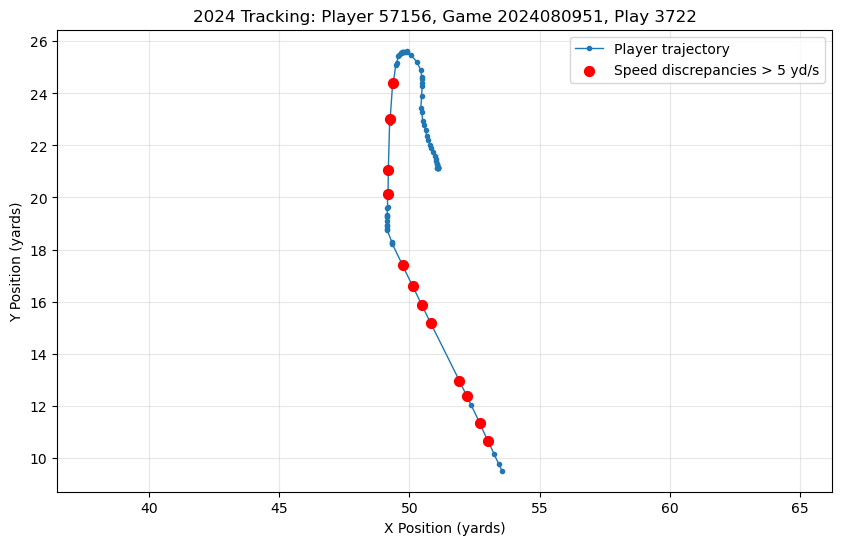

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    player_play["x"],
    player_play["y"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Player trajectory"
)

plt.scatter(
    anomaly_rows["x"],
    anomaly_rows["y"],
    color="red",
    s=50,
    label="Speed discrepancies > 5 yd/s",
    zorder=3
)

plt.xlabel("X Position (yards)")
plt.ylabel("Y Position (yards)")
plt.title("2024 Tracking: Player 57156, Game 2024080951, Play 3722")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()

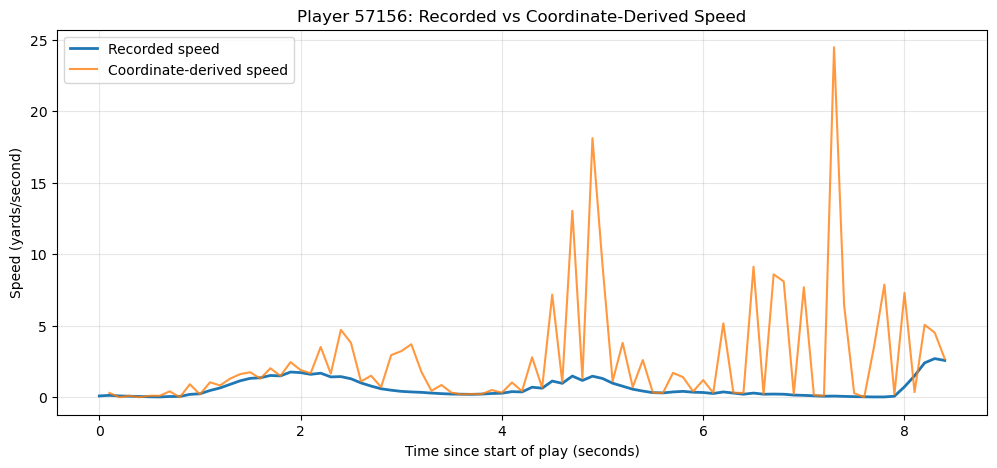

In [98]:
player_play = player_play.sort_values("time").copy()

player_play["elapsed_time"] = (
    pd.to_datetime(player_play["time"]) -
    pd.to_datetime(player_play["time"]).min()
).dt.total_seconds()

plt.figure(figsize=(12, 5))

plt.plot(
    player_play["elapsed_time"],
    player_play["s"],
    label="Recorded speed",
    linewidth=2
)

plt.plot(
    player_play["elapsed_time"],
    player_play["calculated_speed"],
    label="Coordinate-derived speed",
    linewidth=1.5,
    alpha=0.8
)

plt.xlabel("Time since start of play (seconds)")
plt.ylabel("Speed (yards/second)")
plt.title("Player 57156: Recorded vs Coordinate-Derived Speed")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [99]:
valid_play = player_play.loc[
    player_play["dt"].between(0.099, 0.101)
]

coordinate_distance = valid_play["calculated_dis"].sum()

speed_distance = (
    valid_play["s"] * valid_play["dt"]
).sum()

print(f"Coordinate-derived distance: {coordinate_distance:.2f} yards")
print(f"Speed-integrated distance: {speed_distance:.2f} yards")
print(f"Difference: {coordinate_distance - speed_distance:.2f} yards")
print(f"Ratio: {coordinate_distance / speed_distance:.2f}")

Coordinate-derived distance: 22.26 yards
Speed-integrated distance: 5.38 yards
Difference: 16.88 yards
Ratio: 4.14


In [100]:
valid_tracking = tracking_2024_sorted.loc[valid_2024].copy()

valid_tracking["speed_distance"] = (
    valid_tracking["s"] * valid_tracking["dt"]
)

trajectory_quality_2024 = (
    valid_tracking
    .groupby(["game_id", "play_id", "nfl_id"])
    .agg(
        coordinate_distance=("calculated_dis", "sum"),
        speed_distance=("speed_distance", "sum"),
        frame_count=("s", "size")
    )
    .reset_index()
)

trajectory_quality_2024["distance_ratio"] = (
    trajectory_quality_2024["coordinate_distance"] /
    trajectory_quality_2024["speed_distance"].replace(0, np.nan)
)

eligible = trajectory_quality_2024.loc[
    (trajectory_quality_2024["frame_count"] >= 20) &
    (trajectory_quality_2024["speed_distance"] >= 1)
]

print("Eligible trajectories:", len(eligible))

print("\nDistance ratio distribution:")
display(eligible["distance_ratio"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

print("\nTrajectories with ratio > 1.5:",
      (eligible["distance_ratio"] > 1.5).sum())

print("Trajectories with ratio > 2:",
      (eligible["distance_ratio"] > 2).sum())

print("\nTop 10 largest ratios:")
display(
    eligible.nlargest(10, "distance_ratio")
)

Eligible trajectories: 107897

Distance ratio distribution:


count    107897.000000
mean          1.021472
std           0.043326
min           0.813897
1%            0.983339
5%            0.991428
25%           0.999866
50%           1.010909
75%           1.035878
95%           1.073068
99%           1.111729
max           5.750460
Name: distance_ratio, dtype: float64


Trajectories with ratio > 1.5: 49
Trajectories with ratio > 2: 19

Top 10 largest ratios:


,game_id,play_id,nfl_id,coordinate_distance,speed_distance,frame_count,distance_ratio
58336,2024110310,2658,57145,11.098387,1.930,85,5.750460
58316,2024110310,2445,57179,11.264022,2.221,76,5.071599
1292,2024080951,3722,57156,22.256221,5.378,84,4.138382
1163,2024080951,2564,57156,6.239247,1.631,48,3.825412
58343,2024110310,2763,56347,7.345026,1.951,62,3.764750
1315,2024080951,3821,57156,7.996997,2.566,60,3.116523
41406,2024101302,442,55943,16.217675,5.415,70,2.994954
1298,2024080951,3747,57156,16.558494,5.960,74,2.778271
58346,2024110310,2786,57145,13.504375,5.330,93,2.533654
58318,2024110310,2499,57179,15.861339,6.393,73,2.481048


In [101]:
problem_trajectories_2024 = eligible.loc[
    eligible["distance_ratio"] > 1.5
].copy()

game_quality_2024 = (
    problem_trajectories_2024
    .groupby("game_id")
    .agg(
        problematic_trajectories=("nfl_id", "size"),
        affected_players=("nfl_id", "nunique"),
        max_distance_ratio=("distance_ratio", "max")
    )
    .sort_values("problematic_trajectories", ascending=False)
)

print("Games with problematic trajectories:", len(game_quality_2024))

print("\nTop 15 games:")
display(game_quality_2024.head(15))

print("\nPercentage of problematic trajectories in top 5 games:")
print(
    100 *
    game_quality_2024["problematic_trajectories"].head(5).sum() /
    len(problem_trajectories_2024)
)

Games with problematic trajectories: 21

Top 15 games:


,problematic_trajectories,affected_players,max_distance_ratio
game_id,,,
2024080951,13,1,4.138382
2024110310,13,4,5.750460
2025012600,4,1,2.255497
2025010401,2,2,1.848392
2024082252,1,1,1.561069
2024090812,1,1,1.896066
2025011901,1,1,1.583687
2025010512,1,1,2.368886
2025010510,1,1,1.519521



Percentage of problematic trajectories in top 5 games:
67.34693877551021


In [102]:
game_quality_rates_2024 = (
    eligible
    .assign(problematic=lambda df: df["distance_ratio"] > 1.5)
    .groupby("game_id")
    .agg(
        total_trajectories=("nfl_id", "size"),
        problematic_trajectories=("problematic", "sum")
    )
)

game_quality_rates_2024["problem_rate"] = (
    game_quality_rates_2024["problematic_trajectories"] /
    game_quality_rates_2024["total_trajectories"]
)

display(
    game_quality_rates_2024.loc[
        game_quality_rates_2024["problematic_trajectories"] > 0
    ]
    .sort_values("problem_rate", ascending=False)
    .head(15)
)

,total_trajectories,problematic_trajectories,problem_rate
game_id,,,
2024110310,277,13,0.046931
2024080951,424,13,0.030660
2025012600,351,4,0.011396
2024092906,125,1,0.008000
2024091200,132,1,0.007576
2024102710,198,1,0.005051
2025010401,398,2,0.005025
2025011901,214,1,0.004673
2024082252,234,1,0.004274


In [103]:
trajectory_quality_2024["qc_flag_distance_ratio"] = (
    (trajectory_quality_2024["frame_count"] >= 20) &
    (trajectory_quality_2024["speed_distance"] >= 1) &
    (trajectory_quality_2024["distance_ratio"] > 1.5)
)

trajectory_quality_2024["qc_flag_low_coverage"] = (
    trajectory_quality_2024["frame_count"] < 20
)

trajectory_quality_2024["qc_flag_low_movement"] = (
    trajectory_quality_2024["speed_distance"] < 1
)

print("Total trajectories:", len(trajectory_quality_2024))

print("\nQuality-control flag counts:")
display(
    trajectory_quality_2024[
        [
            "qc_flag_distance_ratio",
            "qc_flag_low_coverage",
            "qc_flag_low_movement"
        ]
    ].sum()
)

print("\nFlagged trajectory percentage:")
print(
    100 *
    trajectory_quality_2024["qc_flag_distance_ratio"].mean()
)

Total trajectories: 108720

Quality-control flag counts:


qc_flag_distance_ratio     49
qc_flag_low_coverage        5
qc_flag_low_movement      822
dtype: int64


Flagged trajectory percentage:
0.04506990434142752


### move onto 2025 tracking


In [104]:
import pandas as pd
import time

start = time.time()

game_tracking_2025 = pd.read_csv(
    RAW_DATA_DIR / "game_tracking_2025.csv"
)

print("Shape:", game_tracking_2025.shape)
print("Memory usage (GB):", round(
    game_tracking_2025.memory_usage(deep=True).sum() / 1e9, 3
))
print("Load time (seconds):", round(time.time() - start, 2))

print("\nColumn names:")
print(game_tracking_2025.columns.tolist())

print("\nData types:")
display(game_tracking_2025.dtypes)

print("\nFirst five rows:")
display(game_tracking_2025.head())

Shape: (11160903, 12)
Memory usage (GB): 2.075
Load time (seconds): 12.65

Column names:
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']

Data types:


game_id      int64
play_id      int64
nfl_id       int64
time        object
x          float64
y          float64
s          float64
a          float64
dis        float64
o          float64
dir        float64
event       object
dtype: object


First five rows:


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2025090701,290,57347,2025-09-07T17:09:39.500,83.06,32.06,0.10,0.06,0.04,8.00,18.86,NaN
1,2025090701,290,57347,2025-09-07T17:09:39.600,83.07,32.07,0.10,0.07,0.02,2.61,21.95,NaN
2,2025090701,290,57347,2025-09-07T17:09:39.700,83.06,32.06,0.07,0.05,0.02,357.42,16.24,NaN
3,2025090701,290,57347,2025-09-07T17:09:39.800,83.07,32.07,0.07,0.05,0.01,352.73,18.93,NaN
4,2025090701,290,57347,2025-09-07T17:09:39.900,83.08,32.07,0.06,0.05,0.01,349.52,20.80,NaN


In [105]:
missing_2025 = pd.DataFrame({
    "missing_count": game_tracking_2025.isna().sum(),
    "missing_pct": game_tracking_2025.isna().mean() * 100
})

display(missing_2025.round(4))

print("Exact duplicate rows:", game_tracking_2025.duplicated().sum())

print(
    "Duplicate tracking keys:",
    game_tracking_2025.duplicated(
        subset=["game_id", "play_id", "nfl_id", "time"]
    ).sum()
)

print("Unique games:", game_tracking_2025["game_id"].nunique())
print("Unique players:", game_tracking_2025["nfl_id"].nunique())

print(
    "Unique plays:",
    game_tracking_2025[
        ["game_id", "play_id"]
    ].drop_duplicates().shape[0]
)

,missing_count,missing_pct
game_id,0,0.0000
play_id,0,0.0000
nfl_id,0,0.0000
time,0,0.0000
x,0,0.0000
y,0,0.0000
s,0,0.0000
a,0,0.0000
dis,0,0.0000
o,0,0.0000


Exact duplicate rows: 0
Duplicate tracking keys: 0
Unique games: 334
Unique players: 448
Unique plays: 42544


In [106]:
numeric_cols_2025 = ["x", "y", "s", "a", "dis", "o", "dir"]

display(
    game_tracking_2025[numeric_cols_2025]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
    .T
    .round(3)
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
x,11160903.0,59.988,24.554,-5.860,10.18,18.95,41.81,59.98,78.25,100.91,109.79,127.400
y,11160903.0,26.738,9.133,-8.780,3.95,10.67,21.33,26.75,32.13,42.81,49.65,63.050
s,11160903.0,2.471,2.049,0.000,0.00,0.00,0.81,2.05,3.68,6.57,8.12,16.880
a,11160903.0,1.553,1.199,-14.396,0.00,0.01,0.64,1.34,2.22,3.88,5.14,33.759
dis,11160903.0,0.252,0.206,0.000,0.00,0.00,0.08,0.21,0.37,0.66,0.82,4.200
o,11160903.0,178.969,100.477,0.000,4.88,24.74,89.52,179.17,269.30,334.05,355.01,360.000
dir,11160903.0,180.085,103.193,0.000,3.45,18.22,90.46,179.87,269.69,341.90,356.52,360.000


Once more there are some extreme values that are not plausible.

In [107]:
field_checks_2025 = {
    "x_outside_field": (
        (game_tracking_2025["x"] < 0) |
        (game_tracking_2025["x"] > 120)
    ),
    "y_outside_field": (
        (game_tracking_2025["y"] < 0) |
        (game_tracking_2025["y"] > 53.33)
    ),
    "speed_above_10": game_tracking_2025["s"] > 10,
    "acceleration_above_10": game_tracking_2025["a"] > 10,
    "negative_acceleration": game_tracking_2025["a"] < 0,
    "displacement_above_1": game_tracking_2025["dis"] > 1,
    "orientation_outside_range": (
        (game_tracking_2025["o"] < 0) |
        (game_tracking_2025["o"] > 360)
    ),
    "direction_outside_range": (
        (game_tracking_2025["dir"] < 0) |
        (game_tracking_2025["dir"] > 360)
    )
}

field_summary_2025 = pd.DataFrame({
    "count": {k: v.sum() for k, v in field_checks_2025.items()},
    "percentage": {
        k: 100 * v.mean()
        for k, v in field_checks_2025.items()
    }
})

display(field_summary_2025.round(5))

,count,percentage
x_outside_field,2121,0.01900
y_outside_field,37196,0.33327
speed_above_10,1051,0.00942
acceleration_above_10,108,0.00097
negative_acceleration,82,0.00073
displacement_above_1,1354,0.01213
orientation_outside_range,0,0.00000
direction_outside_range,0,0.00000


In [108]:
extreme_dis_2025 = game_tracking_2025.nlargest(20, "dis")

display(
    extreme_dis_2025[
        [
            "game_id",
            "play_id",
            "nfl_id",
            "time",
            "x",
            "y",
            "s",
            "a",
            "dis"
        ]
    ]
)

print(
    "Players with displacement > 1:",
    game_tracking_2025.loc[
        game_tracking_2025["dis"] > 1, "nfl_id"
    ].nunique()
)

print(
    "Games with displacement > 1:",
    game_tracking_2025.loc[
        game_tracking_2025["dis"] > 1, "game_id"
    ].nunique()
)

print(
    "Plays with displacement > 1:",
    game_tracking_2025.loc[
        game_tracking_2025["dis"] > 1,
        ["game_id", "play_id"]
    ].drop_duplicates().shape[0]
)

,game_id,play_id,nfl_id,time,x,y,s,a,dis
5195333,2026010300,1114,58413,2026-01-03T22:15:17.800,93.19,35.73,1.64,4.22,4.20
5195303,2026010300,1114,58413,2026-01-03T22:15:14.800,89.00,25.97,0.16,0.52,4.12
9487146,2025082358,3845,57339,2025-08-24T02:19:08.600,113.66,7.06,5.63,9.19,2.58
7182529,2025110908,3999,56062,2025-11-09T23:57:46.500,17.36,55.67,8.68,1.51,2.51
5195304,2026010300,1114,58413,2026-01-03T22:15:14.900,89.01,28.36,0.15,0.49,2.39
4161673,2026010300,1012,58327,2026-01-03T22:11:54.700,92.02,30.41,2.18,3.17,2.38
4588639,2025081655,3054,56003,2025-08-16T19:23:01.000,21.94,55.53,7.52,4.18,2.37
4884156,2025091400,1025,58229,2025-09-14T17:43:34.300,67.09,-2.16,7.90,2.84,2.34
4665055,2025113003,3254,58298,2025-11-30T20:24:38.100,7.33,34.69,10.77,12.72,2.29
7584804,2025101200,1489,57223,2025-10-12T14:34:17.500,62.49,55.33,9.11,2.57,2.24


Players with displacement > 1: 159
Games with displacement > 1: 208
Plays with displacement > 1: 409


In [109]:
#INvestigate player 58413
trajectory = game_tracking_2025.loc[
    (game_tracking_2025["game_id"] == 2026010300) &
    (game_tracking_2025["play_id"] == 1114) &
    (game_tracking_2025["nfl_id"] == 58413),
    ["time", "x", "y", "s", "a", "dis"]
].sort_values("time").copy()

trajectory["dt"] = (
    pd.to_datetime(trajectory["time"])
    .diff()
    .dt.total_seconds()
)

trajectory["calculated_dis"] = (
    trajectory["x"].diff().pow(2) +
    trajectory["y"].diff().pow(2)
).pow(0.5)

trajectory["calculated_speed"] = (
    trajectory["calculated_dis"] / trajectory["dt"]
)

trajectory["dis_error"] = (
    trajectory["dis"] - trajectory["calculated_dis"]
)

print("Total frames:", len(trajectory))

display(
    trajectory.nlargest(10, "calculated_dis")
)

Total frames: 75


,time,x,y,s,a,dis,dt,calculated_dis,calculated_speed,dis_error
5195333,2026-01-03T22:15:17.800,93.19,35.73,1.64,4.22,4.20,0.1,4.204295,42.042954,-4.295423e-03
5195303,2026-01-03T22:15:14.800,89.00,25.97,0.16,0.52,4.12,0.1,4.120000,41.200000,2.664535e-15
5195304,2026-01-03T22:15:14.900,89.01,28.36,0.15,0.49,2.39,0.1,2.390021,23.900209,-2.092041e-05
5195330,2026-01-03T22:15:17.500,92.93,40.11,1.13,1.58,2.03,0.1,2.040392,20.403921,-1.039212e-02
5195311,2026-01-03T22:15:15.600,89.56,32.32,2.90,2.88,1.61,0.1,1.610124,16.101242,-1.242188e-04
5195339,2026-01-03T22:15:18.400,94.11,31.92,0.60,1.71,1.60,0.1,1.600312,16.003125,-3.124695e-04
5195328,2026-01-03T22:15:17.300,92.81,42.10,1.16,6.38,1.46,0.1,1.450862,14.508618,9.138187e-03
5195313,2026-01-03T22:15:15.800,89.91,33.98,5.07,7.00,1.42,0.1,1.414390,14.143903,5.609672e-03
5195309,2026-01-03T22:15:15.400,89.25,30.66,1.32,0.12,1.28,0.1,1.287245,12.872451,-7.245120e-03
5195317,2026-01-03T22:15:16.200,90.60,37.06,9.35,5.30,1.16,0.1,1.152085,11.520851,7.914934e-03


In [110]:
import numpy as np

tracking_2025_qc = game_tracking_2025[
    ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "dis"]
].sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
).reset_index(drop=True)

groups_2025 = tracking_2025_qc.groupby(
    ["game_id", "play_id", "nfl_id"],
    sort=False
)

dt_2025 = (
    pd.to_datetime(tracking_2025_qc["time"])
    .groupby([
        tracking_2025_qc["game_id"],
        tracking_2025_qc["play_id"],
        tracking_2025_qc["nfl_id"]
    ])
    .diff()
    .dt.total_seconds()
)

dx_2025 = groups_2025["x"].diff()
dy_2025 = groups_2025["y"].diff()

calculated_dis_2025 = np.hypot(dx_2025, dy_2025)

valid_2025 = dt_2025.between(0.099, 0.101)

calculated_speed_2025 = calculated_dis_2025 / dt_2025

dis_error_2025 = tracking_2025_qc["dis"] - calculated_dis_2025
speed_error_2025 = calculated_speed_2025 - tracking_2025_qc["s"]

print("Valid consecutive frame pairs:", valid_2025.sum())

print("\nDisplacement consistency:")
print("Mean absolute error:", dis_error_2025[valid_2025].abs().mean())
print("Correlation:", tracking_2025_qc.loc[valid_2025, "dis"].corr(calculated_dis_2025[valid_2025]))
print("Errors > 0.5 yd:", (dis_error_2025[valid_2025].abs() > 0.5).sum())

print("\nSpeed consistency:")
print("Mean absolute error:", speed_error_2025[valid_2025].abs().mean())
print("Correlation:", tracking_2025_qc.loc[valid_2025, "s"].corr(calculated_speed_2025[valid_2025]))
print("Errors > 5 yd/s:", (speed_error_2025[valid_2025].abs() > 5).sum())
print("Calculated speeds > 12 yd/s:", (calculated_speed_2025[valid_2025] > 12).sum())

Valid consecutive frame pairs: 11005588

Displacement consistency:
Mean absolute error: 0.0037900298740418136
Correlation: 0.9996597964264686
Errors > 0.5 yd: 13

Speed consistency:
Mean absolute error: 0.09688123549116891
Correlation: 0.9971211573466161
Errors > 5 yd/s: 715
Calculated speeds > 12 yd/s: 257


In [111]:
speed_anomalies_2025 = tracking_2025_qc.loc[
    valid_2025 & (speed_error_2025.abs() > 5),
    ["game_id", "play_id", "nfl_id", "time", "s", "dis"]
].copy()

speed_anomalies_2025["calculated_speed"] = (
    calculated_speed_2025.loc[speed_anomalies_2025.index]
)

speed_anomalies_2025["speed_error"] = (
    speed_error_2025.loc[speed_anomalies_2025.index]
)

print("Anomalous frames:", len(speed_anomalies_2025))
print("Affected players:", speed_anomalies_2025["nfl_id"].nunique())
print("Affected games:", speed_anomalies_2025["game_id"].nunique())

print(
    "Affected plays:",
    speed_anomalies_2025[
        ["game_id", "play_id"]
    ].drop_duplicates().shape[0]
)

print("\nTop 10 players by anomaly count:")
display(
    speed_anomalies_2025["nfl_id"]
    .value_counts()
    .head(10)
)

print("\nSpeed error distribution:")
display(speed_anomalies_2025["speed_error"].describe())

print("\nLargest discrepancies:")
display(
    speed_anomalies_2025.nlargest(
        10, "speed_error"
    )
)


Anomalous frames: 715
Affected players: 190
Affected games: 186
Affected plays: 401

Top 10 players by anomaly count:


nfl_id
55924    52
58370    49
57155    43
58413    35
55928    23
57217    23
58363    17
58249    16
57136    15
58360    15
Name: count, dtype: int64


Speed error distribution:


count    715.000000
mean       5.643000
std        7.369083
min      -10.270000
25%        5.098849
50%        6.583034
75%        9.958884
max       41.040000
Name: speed_error, dtype: float64


Largest discrepancies:


,game_id,play_id,nfl_id,time,s,dis,calculated_speed,speed_error
10096715,2026010300,1114,58413,2026-01-03T22:15:14.800,0.160,4.120,41.200000,41.040000
10096745,2026010300,1114,58413,2026-01-03T22:15:17.800,1.640,4.200,42.042954,40.402954
4328578,2025101205,1289,58360,2025-10-12T17:54:03.800,6.451,0.645,36.446109,29.995109
4328800,2025101205,1314,58360,2025-10-12T17:54:46.000,2.875,0.287,29.073887,26.198887
10096716,2026010300,1114,58413,2026-01-03T22:15:14.900,0.150,2.390,23.900209,23.750209
4328670,2025101205,1289,58370,2025-10-12T17:54:03.800,3.072,0.307,24.811263,21.739263
10095633,2026010300,1012,58327,2026-01-03T22:11:54.700,2.180,2.380,23.726146,21.546146
1513815,2025082358,3845,57339,2025-08-24T02:19:08.600,5.630,2.580,25.856527,20.226527
10096742,2026010300,1114,58413,2026-01-03T22:15:17.500,1.130,2.030,20.403921,19.273921
4328417,2025101205,1289,57155,2025-10-12T17:53:56.700,0.000,0.000,19.184247,19.184247


In [112]:
valid_indices_2025 = np.flatnonzero(valid_2025.to_numpy())

trajectory_quality_2025 = tracking_2025_qc.iloc[
    valid_indices_2025
][["game_id", "play_id", "nfl_id"]].copy()

trajectory_quality_2025["coordinate_distance"] = (
    calculated_dis_2025.iloc[valid_indices_2025].to_numpy()
)

trajectory_quality_2025["speed_distance"] = (
    tracking_2025_qc["s"].iloc[valid_indices_2025].to_numpy() *
    dt_2025.iloc[valid_indices_2025].to_numpy()
)

trajectory_quality_2025 = (
    trajectory_quality_2025
    .groupby(["game_id", "play_id", "nfl_id"])
    .agg(
        coordinate_distance=("coordinate_distance", "sum"),
        speed_distance=("speed_distance", "sum"),
        frame_count=("coordinate_distance", "size")
    )
    .reset_index()
)

trajectory_quality_2025["distance_ratio"] = (
    trajectory_quality_2025["coordinate_distance"] /
    trajectory_quality_2025["speed_distance"].replace(0, np.nan)
)

eligible_2025 = trajectory_quality_2025.loc[
    (trajectory_quality_2025["frame_count"] >= 20) &
    (trajectory_quality_2025["speed_distance"] >= 1)
]

print("Eligible trajectories:", len(eligible_2025))

print("\nDistance ratio distribution:")
display(
    eligible_2025["distance_ratio"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

print("\nTrajectories with ratio > 1.5:",
      (eligible_2025["distance_ratio"] > 1.5).sum())

print("Trajectories with ratio > 2:",
      (eligible_2025["distance_ratio"] > 2).sum())

print("\nTop 10 largest ratios:")
display(eligible_2025.nlargest(10, "distance_ratio"))

Eligible trajectories: 153915

Distance ratio distribution:


count    153915.000000
mean          1.025628
std           0.045942
min           0.519250
1%            0.985673
5%            0.993456
25%           1.001172
50%           1.019562
75%           1.040025
95%           1.080224
99%           1.133392
max           7.397864
Name: distance_ratio, dtype: float64


Trajectories with ratio > 1.5: 83
Trajectories with ratio > 2: 24

Top 10 largest ratios:


,game_id,play_id,nfl_id,coordinate_distance,speed_distance,frame_count,distance_ratio
86982,2025110904,1886,55924,8.263414,1.117,73,7.397864
87060,2025110904,2381,55924,11.156618,2.111,66,5.284992
87123,2025110904,2801,55924,7.506150,1.610,85,4.662205
87051,2025110904,2334,55924,4.791947,1.036,82,4.625432
87038,2025110904,2263,55924,3.768079,1.115,87,3.379443
87005,2025110904,2074,55924,6.116001,1.907,77,3.207132
86995,2025110904,2008,55924,5.212909,1.747,98,2.983921
17401,2025082252,3050,58963,4.101346,1.400,55,2.929533
17399,2025082252,3050,58940,3.411872,1.166,55,2.926134
87126,2025110904,2827,55924,5.869012,2.094,92,2.802776


In [113]:
problem_trajectories_2025 = eligible_2025.loc[
    eligible_2025["distance_ratio"] > 1.5
]

print("Problematic trajectories:", len(problem_trajectories_2025))

print("\nAffected games:",
      problem_trajectories_2025["game_id"].nunique())

print("Affected players:",
      problem_trajectories_2025["nfl_id"].nunique())

print("\nTop 10 games:")
display(
    problem_trajectories_2025
    .groupby("game_id")
    .agg(
        problematic_trajectories=("nfl_id", "size"),
        affected_players=("nfl_id", "nunique"),
        max_distance_ratio=("distance_ratio", "max")
    )
    .sort_values("problematic_trajectories", ascending=False)
    .head(10)
)

print("\nTop 10 players:")
display(
    problem_trajectories_2025["nfl_id"]
    .value_counts()
    .head(10)
)

print("\nTrajectories with ratio < 0.8:",
      (eligible_2025["distance_ratio"] < 0.8).sum())

Problematic trajectories: 83

Affected games: 37
Affected players: 37

Top 10 games:


,problematic_trajectories,affected_players,max_distance_ratio
game_id,,,
2025110904,30,3,7.397864
2026010300,4,2,2.491110
2025122810,3,3,2.328582
2025082252,3,3,2.929533
2025110206,2,2,1.787244
2025112301,2,2,2.648287
2025113002,2,1,1.810961
2025120704,2,2,2.782975
2025100200,2,1,1.873109



Top 10 players:


nfl_id
55924    28
55930     5
58253     4
57172     3
57473     2
58458     2
58413     2
57278     2
56095     2
58314     2
Name: count, dtype: int64


Trajectories with ratio < 0.8: 10


In [114]:
low_ratio_2025 = eligible_2025.loc[
    eligible_2025["distance_ratio"] < 0.8
].sort_values("distance_ratio")

print("Low-ratio trajectories:", len(low_ratio_2025))

print("Affected games:", low_ratio_2025["game_id"].nunique())
print("Affected players:", low_ratio_2025["nfl_id"].nunique())

display(low_ratio_2025)

print("\nLow-ratio trajectories by game:")
display(
    low_ratio_2025["game_id"].value_counts()
)

print("\nLow-ratio trajectories by player:")
display(
    low_ratio_2025["nfl_id"].value_counts()
)

Low-ratio trajectories: 10
Affected games: 2
Affected players: 8


,game_id,play_id,nfl_id,coordinate_distance,speed_distance,frame_count,distance_ratio
45353,2025092800,62,56497,14.329754,27.5970,40,0.519250
45355,2025092800,62,57172,9.480918,17.3040,40,0.547903
45352,2025092800,62,55958,11.886252,21.3070,40,0.557857
60887,2025101205,1289,58370,45.817687,67.0723,91,0.683109
60885,2025101205,1289,57155,41.369617,59.6185,89,0.693906
60890,2025101205,1314,58363,31.209741,43.5481,64,0.716673
60888,2025101205,1314,57155,33.199033,45.9538,64,0.722444
45351,2025092800,62,55878,6.193448,8.4540,40,0.732606
60891,2025101205,1314,58370,40.576454,52.8243,64,0.768140
60886,2025101205,1289,58360,46.035969,59.2058,91,0.777558



Low-ratio trajectories by game:


game_id
2025101205    6
2025092800    4
Name: count, dtype: int64


Low-ratio trajectories by player:


nfl_id
58370    2
57155    2
56497    1
57172    1
55958    1
58363    1
55878    1
58360    1
Name: count, dtype: int64

In [115]:
inspect_2025 = tracking_2025_qc.loc[
    (tracking_2025_qc["game_id"] == 2025092800) &
    (tracking_2025_qc["play_id"] == 62),
    ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "dis"]
].copy()

inspect_2025["dt"] = dt_2025.loc[inspect_2025.index]
inspect_2025["calculated_dis"] = calculated_dis_2025.loc[inspect_2025.index]
inspect_2025["calculated_speed"] = calculated_speed_2025.loc[inspect_2025.index]

inspect_2025["speed_error"] = (
    inspect_2025["calculated_speed"] - inspect_2025["s"]
)

inspect_2025 = inspect_2025.loc[
    inspect_2025["dt"].between(0.099, 0.101)
]

print("Players in play:", inspect_2025["nfl_id"].nunique())

display(
    inspect_2025.groupby("nfl_id").agg(
        frames=("s", "size"),
        mean_recorded_speed=("s", "mean"),
        mean_calculated_speed=("calculated_speed", "mean"),
        mean_speed_error=("speed_error", "mean"),
        max_absolute_error=("speed_error", lambda x: x.abs().max())
    ).round(3)
)

Players in play: 6


,frames,mean_recorded_speed,mean_calculated_speed,mean_speed_error,max_absolute_error
nfl_id,,,,,
55878,40,2.114,1.548,-0.565,1.954
55958,40,5.327,2.972,-2.355,6.285
56497,40,6.899,3.582,-3.317,6.556
57141,40,2.135,1.839,-0.296,3.373
57172,40,4.326,2.370,-1.956,4.196
57240,40,1.786,1.461,-0.325,3.420


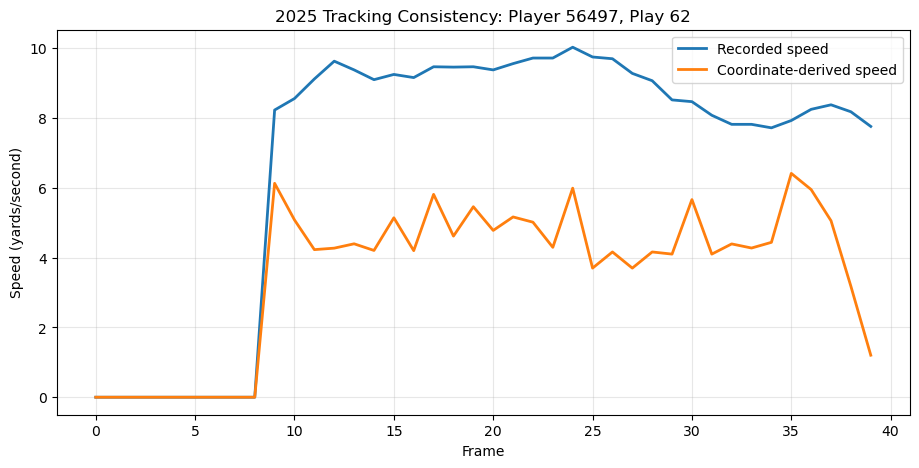

In [116]:
player_check = inspect_2025.loc[
    inspect_2025["nfl_id"] == 56497
].sort_values("time")

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    range(len(player_check)),
    player_check["s"],
    label="Recorded speed",
    linewidth=2
)

plt.plot(
    range(len(player_check)),
    player_check["calculated_speed"],
    label="Coordinate-derived speed",
    linewidth=2
)

plt.xlabel("Frame")
plt.ylabel("Speed (yards/second)")
plt.title("2025 Tracking Consistency: Player 56497, Play 62")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [117]:
frame_consistency_2025 = (
    inspect_2025
    .assign(
        absolute_speed_error=lambda df: df["speed_error"].abs(),
        relative_speed_error=lambda df: (
            df["speed_error"].abs() /
            df["s"].clip(lower=1)
        )
    )
    .groupby("nfl_id")
    .agg(
        frames=("s", "size"),
        mean_absolute_error=("absolute_speed_error", "mean"),
        median_absolute_error=("absolute_speed_error", "median"),
        frames_error_gt_2=("absolute_speed_error", lambda x: (x > 2).sum()),
        frames_relative_error_gt_25pct=("relative_speed_error", lambda x: (x > 0.25).sum())
    )
)

frame_consistency_2025["pct_frames_error_gt_2"] = (
    100 *
    frame_consistency_2025["frames_error_gt_2"] /
    frame_consistency_2025["frames"]
)

display(frame_consistency_2025.round(3))

,frames,mean_absolute_error,median_absolute_error,frames_error_gt_2,frames_relative_error_gt_25pct,pct_frames_error_gt_2
nfl_id,,,,,,
55878,40,0.659,0.532,0,19,0.0
55958,40,2.565,2.180,22,24,55.0
56497,40,3.317,3.995,30,30,75.0
57141,40,1.084,1.068,7,26,17.5
57172,40,1.973,2.401,24,26,60.0
57240,40,1.122,0.895,8,25,20.0


In [118]:
import pandas as pd

print("Shape:", game_tracking_2023.shape)

print("\nColumns:")
print(game_tracking_2023.columns.tolist())

print("\nMissing values:")
display(game_tracking_2023.isna().sum())

print("\nDuplicate tracking keys:")
print(
    game_tracking_2023.duplicated(
        subset=["game_id", "play_id", "nfl_id", "time"]
    ).sum()
)

print("\nUnique games:", game_tracking_2023["game_id"].nunique())

print(
    "Unique plays:",
    game_tracking_2023[["game_id", "play_id"]]
    .drop_duplicates()
    .shape[0]
)

print("Unique players:", game_tracking_2023["nfl_id"].nunique())

print("\nTracking interval distribution:")

sample_2023 = (
    game_tracking_2023[
        ["game_id", "play_id", "nfl_id", "time"]
    ]
    .sort_values(["game_id", "play_id", "nfl_id", "time"])
    .copy()
)

sample_2023["dt"] = (
    pd.to_datetime(sample_2023["time"])
    .groupby([
        sample_2023["game_id"],
        sample_2023["play_id"],
        sample_2023["nfl_id"]
    ])
    .diff()
    .dt.total_seconds()
)

display(sample_2023["dt"].value_counts().head(10))


Shape: (3665443, 12)

Columns:
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']

Missing values:


game_id          0
play_id          0
nfl_id           0
time             0
x                0
y                0
s                0
a                0
dis              0
o                0
dir              0
event      3422066
dtype: int64


Duplicate tracking keys:
0

Unique games: 333
Unique plays: 31690
Unique players: 156

Tracking interval distribution:


dt
0.1    3614529
0.2          3
Name: count, dtype: int64

In [119]:
import numpy as np

tracking_2023_qc = game_tracking_2023[
    ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "dis"]
].sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
).reset_index(drop=True)

groups_2023 = tracking_2023_qc.groupby(
    ["game_id", "play_id", "nfl_id"],
    sort=False
)

dt_2023 = (
    pd.to_datetime(tracking_2023_qc["time"])
    .groupby([
        tracking_2023_qc["game_id"],
        tracking_2023_qc["play_id"],
        tracking_2023_qc["nfl_id"]
    ])
    .diff()
    .dt.total_seconds()
)

dx_2023 = groups_2023["x"].diff()
dy_2023 = groups_2023["y"].diff()

calculated_dis_2023 = np.hypot(dx_2023, dy_2023)

valid_2023 = dt_2023.between(0.099, 0.101)

calculated_speed_2023 = calculated_dis_2023 / dt_2023

dis_error_2023 = tracking_2023_qc["dis"] - calculated_dis_2023
speed_error_2023 = calculated_speed_2023 - tracking_2023_qc["s"]

print("Valid consecutive frame pairs:", valid_2023.sum())

print("\nDisplacement consistency:")
print("Mean absolute error:", dis_error_2023[valid_2023].abs().mean())
print("Correlation:", tracking_2023_qc.loc[valid_2023, "dis"].corr(calculated_dis_2023[valid_2023]))
print("Errors > 0.5 yd:", (dis_error_2023[valid_2023].abs() > 0.5).sum())

print("\nSpeed consistency:")
print("Mean absolute error:", speed_error_2023[valid_2023].abs().mean())
print("Correlation:", tracking_2023_qc.loc[valid_2023, "s"].corr(calculated_speed_2023[valid_2023]))
print("Errors > 5 yd/s:", (speed_error_2023[valid_2023].abs() > 5).sum())
print("Calculated speeds > 12 yd/s:", (calculated_speed_2023[valid_2023] > 12).sum())

Valid consecutive frame pairs: 3614529

Displacement consistency:
Mean absolute error: 0.0038113162903013077
Correlation: 0.9865800619333778
Errors > 0.5 yd: 11

Speed consistency:
Mean absolute error: 0.09205399610455728
Correlation: 0.9842373843937205
Errors > 5 yd/s: 266
Calculated speeds > 12 yd/s: 128


In [120]:

speed_anomalies_2023 = tracking_2023_qc.loc[
    valid_2023 & (speed_error_2023.abs() > 5),
    ["game_id", "play_id", "nfl_id", "time", "s", "dis"]
].copy()

speed_anomalies_2023["calculated_speed"] = (
    calculated_speed_2023.loc[speed_anomalies_2023.index]
)

speed_anomalies_2023["speed_error"] = (
    speed_error_2023.loc[speed_anomalies_2023.index]
)

print("Anomalous frames:", len(speed_anomalies_2023))
print("Affected players:", speed_anomalies_2023["nfl_id"].nunique())
print("Affected games:", speed_anomalies_2023["game_id"].nunique())

print(
    "Affected plays:",
    speed_anomalies_2023[
        ["game_id", "play_id"]
    ].drop_duplicates().shape[0]
)

print("\nTop 10 players by anomaly count:")
display(
    speed_anomalies_2023["nfl_id"]
    .value_counts()
    .head(10)
)

print("\nSpeed error distribution:")
display(speed_anomalies_2023["speed_error"].describe())

print("\nLargest absolute speed discrepancies:")
display(
    speed_anomalies_2023.reindex(
        speed_anomalies_2023["speed_error"]
        .abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    )
)

Anomalous frames: 266
Affected players: 65
Affected games: 125
Affected plays: 192

Top 10 players by anomaly count:


nfl_id
55922    39
55989    21
56042    14
55915    11
55884    11
55959     9
55904     8
55888     7
56056     7
56034     6
Name: count, dtype: int64


Speed error distribution:


count    266.000000
mean      10.590891
std       40.401262
min       -8.868750
25%        5.341941
50%        6.855621
75%       11.763821
max      405.765659
Name: speed_error, dtype: float64


Largest absolute speed discrepancies:


,game_id,play_id,nfl_id,time,s,dis,calculated_speed,speed_error
47261,2023081151,115,55922,2023-08-11 23:10:44.500,0.00,0.00,405.765659,405.765659
47199,2023081151,93,55922,2023-08-11 23:10:19.900,0.00,0.00,396.609443,396.609443
54149,2023081151,1836,55922,2023-08-12 00:17:08.000,0.00,0.00,340.747252,340.747252
874963,2023091702,2842,55989,2023-09-17 19:02:52.400,0.14,3.44,34.380372,34.240372
818805,2023091011,1759,56075,2023-09-10 21:32:34.400,3.86,3.40,34.059507,30.199507
101521,2023081154,3098,56089,2023-08-12 01:25:19.500,2.25,2.24,22.420749,20.170749
847321,2023091013,3458,56034,2023-09-11 02:55:57.300,1.28,1.92,19.168985,17.888985
2960701,2023122100,3013,56042,2023-12-22 03:23:38.300,6.34,2.28,22.800219,16.460219
1065127,2023092409,1659,55904,2023-09-24 21:18:00.100,3.63,2.00,20.048940,16.418940
1265608,2023100200,2946,55938,2023-10-03 02:26:58.100,6.78,2.32,23.186418,16.406418


In [121]:
regular_2023 = valid_2023 & (calculated_speed_2023 <= 12)

print("Original valid frames:", valid_2023.sum())
print("Frames after sensitivity filter:", regular_2023.sum())

print("\nDisplacement correlation:")
print(
    "Original:",
    tracking_2023_qc.loc[valid_2023, "dis"].corr(
        calculated_dis_2023[valid_2023]
    )
)
print(
    "Filtered:",
    tracking_2023_qc.loc[regular_2023, "dis"].corr(
        calculated_dis_2023[regular_2023]
    )
)

print("\nSpeed correlation:")
print(
    "Original:",
    tracking_2023_qc.loc[valid_2023, "s"].corr(
        calculated_speed_2023[valid_2023]
    )
)
print(
    "Filtered:",
    tracking_2023_qc.loc[regular_2023, "s"].corr(
        calculated_speed_2023[regular_2023]
    )
)

print("\nDisplacement MAE:")
print(
    "Original:", dis_error_2023[valid_2023].abs().mean(),
    "Filtered:", dis_error_2023[regular_2023].abs().mean()
)

print("\nSpeed MAE:")
print(
    "Original:", speed_error_2023[valid_2023].abs().mean(),
    "Filtered:", speed_error_2023[regular_2023].abs().mean()
)

Original valid frames: 3614529
Frames after sensitivity filter: 3614401

Displacement correlation:
Original: 0.9865800619333778
Filtered: 0.9996969797951631

Speed correlation:
Original: 0.9842373843937205
Filtered: 0.9978641833884291

Displacement MAE:
Original: 0.0038113162903013077 Filtered: 0.0037791710668170857

Speed MAE:
Original: 0.09205399610455728 Filtered: 0.09136064878825934


In [122]:
valid_indices_2023 = np.flatnonzero(valid_2023.to_numpy())

trajectory_quality_2023 = tracking_2023_qc.iloc[
    valid_indices_2023
][["game_id", "play_id", "nfl_id"]].copy()

trajectory_quality_2023["coordinate_distance"] = (
    calculated_dis_2023.iloc[valid_indices_2023].to_numpy()
)

trajectory_quality_2023["speed_distance"] = (
    tracking_2023_qc["s"].iloc[valid_indices_2023].to_numpy() *
    dt_2023.iloc[valid_indices_2023].to_numpy()
)

trajectory_quality_2023 = (
    trajectory_quality_2023
    .groupby(["game_id", "play_id", "nfl_id"])
    .agg(
        coordinate_distance=("coordinate_distance", "sum"),
        speed_distance=("speed_distance", "sum"),
        frame_count=("coordinate_distance", "size")
    )
    .reset_index()
)

trajectory_quality_2023["distance_ratio"] = (
    trajectory_quality_2023["coordinate_distance"] /
    trajectory_quality_2023["speed_distance"].replace(0, np.nan)
)

eligible_2023 = trajectory_quality_2023.loc[
    (trajectory_quality_2023["frame_count"] >= 20) &
    (trajectory_quality_2023["speed_distance"] >= 1)
]

print("Eligible trajectories:", len(eligible_2023))

print("\nDistance ratio distribution:")
display(
    eligible_2023["distance_ratio"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

print("\nTrajectories with ratio > 1.5:",
      (eligible_2023["distance_ratio"] > 1.5).sum())

print("Trajectories with ratio > 2:",
      (eligible_2023["distance_ratio"] > 2).sum())

print("Trajectories with ratio < 0.8:",
      (eligible_2023["distance_ratio"] < 0.8).sum())

print("\nTop 10 largest ratios:")
display(eligible_2023.nlargest(10, "distance_ratio"))


Eligible trajectories: 50515

Distance ratio distribution:


count    50515.000000
mean         1.020851
std          0.058712
min          0.633003
1%           0.986424
5%           0.994093
25%          1.002098
50%          1.015091
75%          1.036785
95%          1.052124
99%          1.077368
max          8.547214
Name: distance_ratio, dtype: float64


Trajectories with ratio > 1.5: 25
Trajectories with ratio > 2: 8
Trajectories with ratio < 0.8: 15

Top 10 largest ratios:


,game_id,play_id,nfl_id,coordinate_distance,speed_distance,frame_count,distance_ratio
38008,2023121100,1307,55875,10.136996,1.186,78,8.547214
659,2023081151,115,55922,45.769484,6.235,50,7.340735
759,2023081151,1836,55922,41.626818,6.268,55,6.641164
658,2023081151,93,55922,55.675258,19.248,60,2.892522
40213,2023121709,693,55903,3.960132,1.653,52,2.395724
11870,2023091013,3566,55922,3.584813,1.564,57,2.292080
15471,2023092412,3617,55914,3.902753,1.932,57,2.020058
50112,2024011501,2819,55914,2.083371,1.032,49,2.018771
14397,2023092404,432,56066,2.195337,1.141,40,1.924046
2001,2023081156,4368,56514,3.844936,2.050,62,1.875578


### We can now move on to inspecting the actual data schemas


In [124]:
import pandas as pd

players = pd.read_csv(RAW_DATA_DIR / "players.csv")
combine_results = pd.read_csv(RAW_DATA_DIR / "combine_results.csv")
combine_tracking = pd.read_csv(RAW_DATA_DIR / "combine_tracking.csv")
player_career_successes = pd.read_csv(RAW_DATA_DIR / "player_career_successes.csv")
player_play = pd.read_csv(RAW_DATA_DIR / "player_play.csv")

datasets = {
    "players": players,
    "combine_results": combine_results,
    "combine_tracking": combine_tracking,
    "player_career_successes": player_career_successes,
    "player_play": player_play
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())


PLAYERS
Shape: (510, 10)
Columns: ['nfl_id', 'display_name', 'draft_year', 'nfl_position', 'birth_date', 'college_name', 'college_conference', 'draft_round', 'draft_pick_within_round', 'draft_overall_pick']

COMBINE_RESULTS
Shape: (510, 18)
Columns: ['draft_year', 'nfl_id', 'combine_position', 'combine_height', 'combine_weight', 'hand_size', 'arm_length', 'wing_span', 'ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone', 'short_shuttle', 'bench_reps', 'ngs_athleticism_score', 'ngs_college_production_score', 'ngs_final_score']

COMBINE_TRACKING
Shape: (463189, 14)
Columns: ['draft_year', 'event_id', 'nfl_id', 'entity_type', 'time', 'drill_type', 'drill_name', 'attempt', 'x', 'y', 's', 'a', 'dis', 'dir']

PLAYER_CAREER_SUCCESSES
Shape: (510, 9)
Columns: ['nfl_id', 'career_offensive_snaps', 'career_defensive_snaps', 'career_special_teams_snaps', 'career_games_active', 'career_games_started', 'ap_all_pro_1st_team', 'ap_all_pro_2nd_team', 'pro_bowl_original_ballot']

PLAYER_PLAY

In [125]:
player_datasets = {
    "players": players,
    "combine_results": combine_results,
    "player_career_successes": player_career_successes
}

for name, df in player_datasets.items():
    print(f"\n{name.upper()}")
    print("Rows:", len(df))
    print("Unique nfl_id:", df["nfl_id"].nunique())
    print("Missing nfl_id:", df["nfl_id"].isna().sum())
    print("Duplicate nfl_id:", df["nfl_id"].duplicated().sum())

player_ids = set(players["nfl_id"].dropna())
combine_ids = set(combine_results["nfl_id"].dropna())
career_ids = set(player_career_successes["nfl_id"].dropna())

print("\nPLAYER ID MATCHING")
print("Players missing from combine:", len(player_ids - combine_ids))
print("Combine players missing from players:", len(combine_ids - player_ids))
print("Players missing from career outcomes:", len(player_ids - career_ids))
print("Career outcomes missing from players:", len(career_ids - player_ids))

print("\nAll three ID sets identical:",
      player_ids == combine_ids == career_ids)


PLAYERS
Rows: 510
Unique nfl_id: 510
Missing nfl_id: 0
Duplicate nfl_id: 0

COMBINE_RESULTS
Rows: 510
Unique nfl_id: 510
Missing nfl_id: 0
Duplicate nfl_id: 0

PLAYER_CAREER_SUCCESSES
Rows: 510
Unique nfl_id: 510
Missing nfl_id: 0
Duplicate nfl_id: 0

PLAYER ID MATCHING
Players missing from combine: 0
Combine players missing from players: 0
Players missing from career outcomes: 0
Career outcomes missing from players: 0

All three ID sets identical: True


In [126]:
reference_ids = set(players["nfl_id"])

tracking_datasets = {
    "combine_tracking": combine_tracking,
    "player_play": player_play,
    "game_tracking_2023": game_tracking_2023,
    "game_tracking_2024": game_tracking_2024,
    "game_tracking_2025": game_tracking_2025
}

results = []

for name, df in tracking_datasets.items():
    dataset_ids = set(df["nfl_id"].dropna())

    results.append({
        "dataset": name,
        "rows": len(df),
        "unique_players": len(dataset_ids),
        "players_in_reference": len(dataset_ids & reference_ids),
        "players_not_in_reference": len(dataset_ids - reference_ids),
        "reference_players_missing": len(reference_ids - dataset_ids),
        "missing_nfl_id_rows": df["nfl_id"].isna().sum()
    })

coverage_report = pd.DataFrame(results)

display(coverage_report)


,dataset,rows,unique_players,players_in_reference,players_not_in_reference,reference_players_missing,missing_nfl_id_rows
0,combine_tracking,463189,510,510,0,0,0
1,player_play,314197,497,497,0,13,0
2,game_tracking_2023,3665443,156,156,0,354,0
3,game_tracking_2024,7827944,318,318,0,192,0
4,game_tracking_2025,11160903,448,448,0,62,0


In [127]:
coverage_by_year = players[
    ["nfl_id", "draft_year"]
].copy()

for name, df in tracking_datasets.items():
    player_ids = set(df["nfl_id"].dropna())

    coverage_by_year[name] = (
        coverage_by_year["nfl_id"].isin(player_ids)
    )

draft_year_coverage = (
    coverage_by_year
    .groupby("draft_year")
    .agg(
        total_players=("nfl_id", "count"),
        combine_tracking=("combine_tracking", "sum"),
        player_play=("player_play", "sum"),
        tracking_2023=("game_tracking_2023", "sum"),
        tracking_2024=("game_tracking_2024", "sum"),
        tracking_2025=("game_tracking_2025", "sum")
    )
)

display(draft_year_coverage)

print("\nDraft year distribution:")
print(players["draft_year"].value_counts().sort_index())

,total_players,combine_tracking,player_play,tracking_2023,tracking_2024,tracking_2025
draft_year,,,,,,
2023,160,160,158,156,146,125
2024,177,177,175,0,172,159
2025,173,173,164,0,0,164



Draft year distribution:
draft_year
2023    160
2024    177
2025    173
Name: count, dtype: int64


In [128]:
missing_player_ids = (
    set(players["nfl_id"]) -
    set(player_play["nfl_id"])
)

missing_players = players[
    players["nfl_id"].isin(missing_player_ids)
].merge(
    player_career_successes,
    on="nfl_id",
    how="left",
    validate="one_to_one"
)

display(
    missing_players[
        [
            "nfl_id",
            "display_name",
            "draft_year",
            "nfl_position",
            "draft_overall_pick",
            "career_offensive_snaps",
            "career_defensive_snaps",
            "career_special_teams_snaps",
            "career_games_active",
            "career_games_started"
        ]
    ].sort_values(["draft_year", "nfl_id"])
)

print("\nMissing players by draft year:")
print(missing_players["draft_year"].value_counts().sort_index())

,nfl_id,display_name,draft_year,nfl_position,draft_overall_pick,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
1,56363,Leonard Taylor,2023,TE,NaN,0,0,0,0,0
0,56648,Ikenna Enechukwu,2023,OLB,NaN,0,0,0,0,0
3,57660,Lideatrick Griffin,2024,WR,NaN,0,0,0,0,0
2,57743,Trajan Jeffcoat,2024,DE,NaN,0,0,0,0,0
4,58293,Caleb Ransaw,2025,FS,88.0,0,0,0,0,0
5,58326,David Walker,2025,OLB,121.0,0,0,0,0,0
6,58374,Zah Frazier,2025,CB,169.0,0,0,0,0,0
7,58407,Gavin Bartholomew,2025,TE,202.0,0,0,0,0,0
8,58417,Robert Longerbeam,2025,CB,212.0,0,0,0,0,0
9,58455,John Williams,2025,G,250.0,0,0,0,0,0



Missing players by draft year:
draft_year
2023    2
2024    2
2025    9
Name: count, dtype: int64


All missing players never played a snap in the nfl


In [129]:
key_cols = ["game_id", "play_id", "nfl_id"]

print("Total rows:", len(player_play))

print("\nMissing key values:")
print(player_play[key_cols].isna().sum())

print("\nUnique player-play keys:")
print(player_play[key_cols].drop_duplicates().shape[0])

duplicate_mask = player_play.duplicated(
    subset=key_cols,
    keep=False
)

print("\nRows involved in duplicate keys:", duplicate_mask.sum())

print(
    "Number of duplicated key combinations:",
    player_play.loc[duplicate_mask, key_cols]
    .drop_duplicates()
    .shape[0]
)

print("\nSample duplicate records:")
display(
    player_play.loc[duplicate_mask]
    .sort_values(key_cols)
    .head(10)
)

Total rows: 314197

Missing key values:
game_id    0
play_id    0
nfl_id     0
dtype: int64

Unique player-play keys:
314197

Rows involved in duplicate keys: 0
Number of duplicated key combinations: 0

Sample duplicate records:


,game_id,play_id,team_abbr,nfl_id,lined_up_position,play_description,quarter,down,yards_to_go,possession_team,...,sack,tackle,assist,caused_forced_fumble,recovered_fumble,tackle_for_loss,time_to_pressure,time_to_qb_hurry,coverage_assignment,coverage_assignment_at_snap


In [130]:
key_cols = ["game_id", "play_id", "nfl_id"]

reference_keys = pd.MultiIndex.from_frame(
    player_play[key_cols]
)

results = []

for year, df in [
    (2023, game_tracking_2023),
    (2024, game_tracking_2024),
    (2025, game_tracking_2025)
]:
    tracking_keys = pd.MultiIndex.from_frame(
        df[key_cols].drop_duplicates()
    )

    matched = tracking_keys.isin(reference_keys)

    results.append({
        "season": year,
        "unique_tracking_player_plays": len(tracking_keys),
        "matched_player_plays": matched.sum(),
        "unmatched_player_plays": (~matched).sum(),
        "match_rate_pct": round(matched.mean() * 100, 3)
    })

match_report = pd.DataFrame(results)

display(match_report)

,season,unique_tracking_player_plays,matched_player_plays,unmatched_player_plays,match_rate_pct
0,2023,50911,50462,449,99.118
1,2024,108720,107863,857,99.212
2,2025,155313,154122,1191,99.233


In [131]:
key_cols = ["game_id", "play_id", "nfl_id"]
play_cols = ["game_id", "play_id"]

reference_keys = pd.MultiIndex.from_frame(player_play[key_cols])
reference_plays = pd.MultiIndex.from_frame(
    player_play[play_cols].drop_duplicates()
)

unmatched_results = []

for year, df in [
    (2023, game_tracking_2023),
    (2024, game_tracking_2024),
    (2025, game_tracking_2025)
]:
    unique_keys = df[key_cols].drop_duplicates().copy()

    key_index = pd.MultiIndex.from_frame(unique_keys)

    unmatched = unique_keys.loc[
        ~key_index.isin(reference_keys)
    ].copy()

    unmatched_play_index = pd.MultiIndex.from_frame(
        unmatched[play_cols]
    )

    unmatched["play_exists"] = unmatched_play_index.isin(
        reference_plays
    )

    unmatched_results.append({
        "season": year,
        "unmatched_player_plays": len(unmatched),
        "play_exists_player_missing": unmatched["play_exists"].sum(),
        "entire_play_missing": (~unmatched["play_exists"]).sum(),
        "affected_players": unmatched["nfl_id"].nunique(),
        "affected_games": unmatched["game_id"].nunique()
    })

display(pd.DataFrame(unmatched_results))

,season,unmatched_player_plays,play_exists_player_missing,entire_play_missing,affected_players,affected_games
0,2023,449,308,141,37,178
1,2024,857,807,50,70,241
2,2025,1191,1173,18,114,293


In [132]:
key_cols = ["game_id", "play_id", "nfl_id"]

tracking_keys = pd.concat(
    [
        game_tracking_2023[key_cols].drop_duplicates(),
        game_tracking_2024[key_cols].drop_duplicates(),
        game_tracking_2025[key_cols].drop_duplicates()
    ],
    ignore_index=True
).drop_duplicates()

tracking_index = pd.MultiIndex.from_frame(tracking_keys)
player_play_index = pd.MultiIndex.from_frame(player_play[key_cols])

matched = player_play_index.isin(tracking_index)

print("Total player-play records:", len(player_play))
print("Matched to tracking:", matched.sum())
print("Missing tracking:", (~matched).sum())
print("Match rate (%):", round(matched.mean() * 100, 3))

unmatched_player_play = player_play.loc[~matched].copy()

print("\nUnmatched player-play records by game year:")
print(
    unmatched_player_play["game_id"]
    .astype(str)
    .str[:4]
    .value_counts()
    .sort_index()
)

print("\nPlayers affected:", unmatched_player_play["nfl_id"].nunique())
print("Games affected:", unmatched_player_play["game_id"].nunique())

Total player-play records: 314197
Matched to tracking: 312447
Missing tracking: 1750
Match rate (%): 99.443

Unmatched player-play records by game year:
game_id
2023    266
2024    602
2025    776
2026    106
Name: count, dtype: int64

Players affected: 394
Games affected: 433


In [133]:
print("COMBINE TRACKING OVERVIEW")

print("\nDraft years:")
print(combine_tracking["draft_year"].value_counts().sort_index())

print("\nEntity types:")
print(combine_tracking["entity_type"].value_counts(dropna=False))

print("\nDrill types:")
print(combine_tracking["drill_type"].value_counts(dropna=False))

print("\nDrill names:")
print(combine_tracking["drill_name"].value_counts(dropna=False))

print("\nAttempts:")
print(combine_tracking["attempt"].value_counts(dropna=False).sort_index())

print("\nMissing values in identifying columns:")
print(
    combine_tracking[
        ["draft_year", "event_id", "nfl_id", "entity_type",
         "time", "drill_type", "drill_name", "attempt"]
    ].isna().sum()
)

print("\nUnique events:", combine_tracking["event_id"].nunique())
print("Unique players:", combine_tracking["nfl_id"].nunique())


COMBINE TRACKING OVERVIEW

Draft years:
draft_year
2023    136097
2024    147815
2025    179277
Name: count, dtype: int64

Entity types:
entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64

Drill types:
drill_type
SKILL_DRILLS_WR     120383
SKILL_DRILLS_DB      94623
SKILL_DRILLS_DL      77428
SKILL_DRILLS_OL      61129
FORTY_YARD_DASH      41500
SKILL_DRILLS_TE      37222
THREE_CONE_DRILL     15951
SHORT_SHUTTLE        11690
SKILL_DRILLS_LB       3263
Name: count, dtype: int64

Drill names:
drill_name
FORTY_YARD_DASH                                 41500
GAUNTLET_DRILL                                  38228
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION    21569
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE          18087
THREE_CONE_DRILL                                15951
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION     12845
OVER_SHOULDER_ADJUST                            12149
LINE_DRILL                                      11895
FOUR_BAG_AGILITY_DRILL                  

In [134]:
print("COMBINE TRACKING KEY AUDIT")

key_cols = ["event_id", "nfl_id", "entity_type", "time"]

print("\nTotal rows:", len(combine_tracking))

print("Unique candidate keys:",
      combine_tracking[key_cols].drop_duplicates().shape[0])

print("Duplicate candidate key rows:",
      combine_tracking.duplicated(key_cols).sum())

print("\nUnique event IDs:", combine_tracking["event_id"].nunique())

event_structure = (
    combine_tracking.groupby("event_id")
    .agg(
        players=("nfl_id", "nunique"),
        entity_types=("entity_type", "nunique"),
        drill_names=("drill_name", "nunique"),
        attempts=("attempt", "nunique"),
        draft_years=("draft_year", "nunique"),
        frames=("time", "size")
    )
)

print("\nEvent structure summary:")
display(event_structure.describe().T)

print("\nEvents containing multiple:")
print("Players:", (event_structure["players"] > 1).sum())
print("Drill names:", (event_structure["drill_names"] > 1).sum())
print("Attempts:", (event_structure["attempts"] > 1).sum())
print("Draft years:", (event_structure["draft_years"] > 1).sum())

print("\nSample events:")
display(event_structure.head(10))

COMBINE TRACKING KEY AUDIT

Total rows: 463189
Unique candidate keys: 463189
Duplicate candidate key rows: 0

Unique event IDs: 6310

Event structure summary:


,count,mean,std,min,25%,50%,75%,max
players,6310.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
entity_types,6310.0,1.087322,0.282328,1.0,1.0,1.0,1.0,2.0
drill_names,6310.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
attempts,6310.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
draft_years,6310.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
frames,6310.0,73.405547,28.480784,10.0,51.0,67.0,87.0,292.0



Events containing multiple:
Players: 0
Drill names: 0
Attempts: 0
Draft years: 0

Sample events:


,players,entity_types,drill_names,attempts,draft_years,frames
event_id,,,,,,
20240229100000_1709237434916_000,1,1,1,1,1,54
20240229100000_1709237639326_000,1,1,1,1,1,50
20240229100000_1709237692456_000,1,1,1,1,1,54
20240229100000_1709237757151_000,1,1,1,1,1,51
20240229100000_1709237797792_000,1,1,1,1,1,55
20240229100000_1709237844661_000,1,1,1,1,1,57
20240229100000_1709237889199_000,1,1,1,1,1,55
20240229100000_1709237982082_000,1,1,1,1,1,53
20240229100000_1709238032007_000,1,1,1,1,1,54


In [135]:
combine_time_qc = combine_tracking[
    ["event_id", "entity_type", "time"]
].copy()

combine_time_qc["time"] = pd.to_datetime(
    combine_time_qc["time"],
    errors="coerce"
)

combine_time_qc = combine_time_qc.sort_values(
    ["event_id", "entity_type", "time"]
)

combine_time_qc["dt"] = (
    combine_time_qc
    .groupby(["event_id", "entity_type"])["time"]
    .diff()
    .dt.total_seconds()
)

print("Invalid timestamps:", combine_time_qc["time"].isna().sum())

print("\nTimestamp interval distribution:")
print(
    combine_time_qc["dt"]
    .round(4)
    .value_counts(dropna=False)
    .head(15)
)

print("\nTimestamp interval summary:")
display(combine_time_qc["dt"].describe())

print("\nZero-second intervals:",
      (combine_time_qc["dt"] == 0).sum())

print("Negative intervals:",
      (combine_time_qc["dt"] < 0).sum())

print("Intervals greater than 0.2 seconds:",
      (combine_time_qc["dt"] > 0.2).sum())

print("\nEvents with irregular intervals:")
irregular_events = combine_time_qc.loc[
    combine_time_qc["dt"].notna() &
    ~combine_time_qc["dt"].between(0.099, 0.101),
    "event_id"
]

print(irregular_events.nunique())

Invalid timestamps: 0

Timestamp interval distribution:
dt
0.1    456328
NaN      6861
Name: count, dtype: int64

Timestamp interval summary:


count    4.563280e+05
mean     1.000000e-01
std      8.405230e-13
min      1.000000e-01
25%      1.000000e-01
50%      1.000000e-01
75%      1.000000e-01
max      1.000000e-01
Name: dt, dtype: float64


Zero-second intervals: 0
Negative intervals: 0
Intervals greater than 0.2 seconds: 0

Events with irregular intervals:
0


In [136]:
import numpy as np

combine_player_qc = (
    combine_tracking.loc[
        combine_tracking["entity_type"] == "PLAYER",
        ["event_id", "nfl_id", "time", "x", "y", "s", "a", "dis"]
    ]
    .sort_values(["event_id", "time"])
    .reset_index(drop=True)
)

groups = combine_player_qc.groupby("event_id", sort=False)

dt = (
    pd.to_datetime(combine_player_qc["time"])
    .groupby(combine_player_qc["event_id"])
    .diff()
    .dt.total_seconds()
)

dx = groups["x"].diff()
dy = groups["y"].diff()

calculated_dis = np.hypot(dx, dy)
calculated_speed = calculated_dis / dt

valid = dt.between(0.099, 0.101)

dis_error = combine_player_qc["dis"] - calculated_dis
speed_error = calculated_speed - combine_player_qc["s"]

print("Valid consecutive frames:", valid.sum())

print("\nDisplacement consistency:")
print("MAE:", dis_error[valid].abs().mean())
print("Correlation:", combine_player_qc.loc[valid, "dis"].corr(calculated_dis[valid]))
print("Errors > 0.5 yards:", (dis_error[valid].abs() > 0.5).sum())

print("\nSpeed consistency:")
print("MAE:", speed_error[valid].abs().mean())
print("Correlation:", combine_player_qc.loc[valid, "s"].corr(calculated_speed[valid]))
print("Errors > 5 yd/s:", (speed_error[valid].abs() > 5).sum())
print("Calculated speeds > 12 yd/s:", (calculated_speed[valid] > 12).sum())

Valid consecutive frames: 424784

Displacement consistency:
MAE: 0.19785893617010908
Correlation: 0.9474112656584317
Errors > 0.5 yards: 2

Speed consistency:
MAE: 0.12537664039950439
Correlation: 0.9982817597059045
Errors > 5 yd/s: 0
Calculated speeds > 12 yd/s: 2


In [137]:
print("Recorded dis mean:", combine_player_qc.loc[valid, "dis"].mean())
print("Calculated dis mean:", calculated_dis[valid].mean())
print("Recorded dis median:", combine_player_qc.loc[valid, "dis"].median())
print("Calculated dis median:", calculated_dis[valid].median())
print("Mean signed error:", dis_error[valid].mean())

Recorded dis mean: 0.3036511502137497
Calculated dis mean: 0.49801809888845056
Recorded dis median: 0.221420777
Calculated dis median: 0.5011098790573669
Mean signed error: -0.19436694867470072


In [138]:
expected_dis = combine_player_qc.loc[valid, "s"] * 0.1

print("Correlation dis vs speed-derived distance:",
      combine_player_qc.loc[valid, "dis"].corr(expected_dis))

print("MAE dis vs speed-derived distance:",
      (combine_player_qc.loc[valid, "dis"] - expected_dis).abs().mean())

print("Mean speed-derived distance:", expected_dis.mean())

print("Mean recorded dis:", combine_player_qc.loc[valid, "dis"].mean())


Correlation dis vs speed-derived distance: 0.9456404993447366
MAE dis vs speed-derived distance: 0.19961113049813156
Mean speed-derived distance: 0.4996843969442403
Mean recorded dis: 0.3036511502137497


In [139]:
calculated_acceleration = (
    groups["s"].diff() / dt
)

acceleration_comparison = pd.DataFrame({
    "recorded_a": combine_player_qc.loc[valid, "a"],
    "calculated_a": calculated_acceleration[valid]
}).dropna()

print("Valid acceleration observations:", len(acceleration_comparison))

print("\nRecorded acceleration:")
display(acceleration_comparison["recorded_a"].describe())

print("\nCalculated acceleration:")
display(acceleration_comparison["calculated_a"].describe())

print("\nSigned acceleration correlation:",
      acceleration_comparison["recorded_a"].corr(
          acceleration_comparison["calculated_a"]
      ))

print("\nAbsolute acceleration correlation:",
      acceleration_comparison["recorded_a"].abs().corr(
          acceleration_comparison["calculated_a"].abs()
      ))

print("\nSigned acceleration MAE:",
      (
          acceleration_comparison["recorded_a"] -
          acceleration_comparison["calculated_a"]
      ).abs().mean())

Valid acceleration observations: 424784

Recorded acceleration:


count    424784.000000
mean          2.845102
std           1.852552
min           0.000000
25%           1.273747
50%           2.585938
75%           4.162545
max          10.717722
Name: recorded_a, dtype: float64


Calculated acceleration:


count    424784.000000
mean          1.014555
std           2.353362
min         -10.625712
25%          -0.179922
50%           0.933333
75%           2.466667
max          11.866667
Name: calculated_a, dtype: float64


Signed acceleration correlation: 0.09297807185612031

Absolute acceleration correlation: 0.6300329311524053

Signed acceleration MAE: 2.00350209128094


In [140]:
g = combine_player_qc.groupby("event_id", sort=False)

vx = (
    g["x"].shift(-1) - g["x"].shift(1)
) / 0.2

vy = (
    g["y"].shift(-1) - g["y"].shift(1)
) / 0.2

ax = (
    vx.groupby(combine_player_qc["event_id"]).shift(-1) -
    vx.groupby(combine_player_qc["event_id"]).shift(1)
) / 0.2

ay = (
    vy.groupby(combine_player_qc["event_id"]).shift(-1) -
    vy.groupby(combine_player_qc["event_id"]).shift(1)
) / 0.2

vector_acceleration = np.hypot(ax, ay)

comparison = pd.DataFrame({
    "recorded_a": combine_player_qc["a"],
    "vector_a": vector_acceleration
}).dropna()

print("Valid observations:", len(comparison))

print("\nVector acceleration summary:")
display(comparison["vector_a"].describe())

print("\nCorrelation:",
      comparison["recorded_a"].corr(comparison["vector_a"]))

print("\nMAE:",
      (comparison["recorded_a"] - comparison["vector_a"]).abs().mean())

print("\nMean recorded acceleration:",
      comparison["recorded_a"].mean())

print("Mean vector acceleration:",
      comparison["vector_a"].mean())

Valid observations: 405854

Vector acceleration summary:


count    405854.000000
mean          3.161918
std           1.992652
min           0.000000
25%           1.666666
50%           2.914092
75%           4.487637
max          22.942395
Name: vector_a, dtype: float64


Correlation: 0.9472792701055079

MAE: 0.49409923648168413

Mean recorded acceleration: 2.892184000230796
Mean vector acceleration: 3.1619178529451575


In [141]:
combine_drill_summary = (
    combine_tracking[
        combine_tracking["entity_type"] == "PLAYER"
    ]
    .groupby("drill_type")
    .agg(
        players=("nfl_id", "nunique"),
        events=("event_id", "nunique"),
        frames=("s", "size"),
        mean_speed=("s", "mean"),
        median_speed=("s", "median"),
        max_speed=("s", "max"),
        mean_acceleration=("a", "mean"),
        max_acceleration=("a", "max")
    )
    .sort_values("events", ascending=False)
)

display(combine_drill_summary.round(3))

,players,events,frames,mean_speed,median_speed,max_speed,mean_acceleration,max_acceleration
drill_type,,,,,,,,
SKILL_DRILLS_WR,107,1529,96408,5.898,6.590,10.977,3.168,9.839
SKILL_DRILLS_DB,122,1170,94623,5.160,5.700,10.260,2.575,8.918
SKILL_DRILLS_DL,114,1007,77428,3.969,3.777,9.293,3.053,9.043
SKILL_DRILLS_OL,121,910,61129,3.012,2.507,8.490,2.681,8.142
FORTY_YARD_DASH,418,793,41500,7.823,8.927,11.854,1.913,9.779
SKILL_DRILLS_TE,42,438,29102,5.498,6.467,9.787,2.598,8.599
SHORT_SHUTTLE,170,223,11690,2.818,2.730,6.870,3.925,10.718
THREE_CONE_DRILL,160,203,15951,2.831,2.583,8.110,3.829,9.534
SKILL_DRILLS_LB,4,37,3263,4.456,4.523,8.630,2.876,8.446


In [142]:
combine_event_features = (
    combine_tracking[
        combine_tracking["entity_type"] == "PLAYER"
    ]
    .groupby(
        ["event_id", "nfl_id", "drill_type", "drill_name"],
        as_index=False
    )
    .agg(
        frames=("s", "size"),
        mean_speed=("s", "mean"),
        peak_speed=("s", "max"),
        mean_acceleration=("a", "mean"),
        peak_acceleration=("a", "max")
    )
)

combine_event_features["duration_seconds"] = (
    combine_event_features["frames"] - 1
) * 0.1

event_summary = (
    combine_event_features
    .groupby("drill_type")
    .agg(
        events=("event_id", "size"),
        median_duration=("duration_seconds", "median"),
        median_peak_speed=("peak_speed", "median"),
        p90_peak_speed=("peak_speed", lambda x: x.quantile(0.9)),
        median_peak_acceleration=("peak_acceleration", "median"),
        p90_peak_acceleration=("peak_acceleration", lambda x: x.quantile(0.9))
    )
    .sort_values("events", ascending=False)
)

display(event_summary.round(3))

,events,median_duration,median_peak_speed,p90_peak_speed,median_peak_acceleration,p90_peak_acceleration
drill_type,,,,,,
SKILL_DRILLS_WR,1529,6.1,8.233,9.620,6.728,8.106
SKILL_DRILLS_DB,1170,7.6,8.367,9.237,6.375,7.636
SKILL_DRILLS_DL,1007,7.3,7.361,8.296,6.376,7.488
SKILL_DRILLS_OL,910,4.9,6.776,7.784,4.912,6.162
FORTY_YARD_DASH,793,5.0,10.590,11.248,5.454,6.311
SKILL_DRILLS_TE,438,6.2,8.288,9.195,5.199,7.020
SHORT_SHUTTLE,223,5.0,5.774,6.323,8.123,9.151
THREE_CONE_DRILL,203,7.8,6.605,7.236,6.943,7.675
SKILL_DRILLS_LB,37,9.0,7.823,8.483,6.283,7.804


In [143]:
combine_event_qc = (
    combine_tracking[
        combine_tracking["entity_type"] == "PLAYER"
    ]
    .groupby(
        ["event_id", "nfl_id", "drill_type", "drill_name"],
        as_index=False
    )
    .agg(
        frames=("s", "size"),
        peak_speed=("s", "max"),
        peak_acceleration=("a", "max"),
        mean_speed=("s", "mean")
    )
)

combine_event_qc["duration_seconds"] = (
    combine_event_qc["frames"] - 1
) * 0.1

print("Total events:", len(combine_event_qc))

print("\nEVENT DURATION")
display(
    combine_event_qc["duration_seconds"].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    )
)

print("\nPEAK SPEED")
display(
    combine_event_qc["peak_speed"].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    )
)

print("\nPEAK ACCELERATION")
display(
    combine_event_qc["peak_acceleration"].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    )
)

print("\nTOP 10 HIGHEST SPEED EVENTS")
display(
    combine_event_qc.nlargest(10, "peak_speed")
)

print("\nTOP 10 HIGHEST ACCELERATION EVENTS")
display(
    combine_event_qc.nlargest(10, "peak_acceleration")
)

Total events: 6310

EVENT DURATION


count    6310.000000
mean        6.731918
std         2.416640
min         0.900000
1%          3.000000
5%          4.000000
50%         6.200000
95%        11.200000
99%        15.500000
max        20.800000
Name: duration_seconds, dtype: float64


PEAK SPEED


count    6310.000000
mean        7.944489
std         1.513786
min         0.678458
1%          4.508743
5%          5.710968
50%         7.911247
95%        10.790102
99%        11.309995
max        11.854232
Name: peak_speed, dtype: float64


PEAK ACCELERATION


count    6310.000000
mean        5.943849
std         1.444721
min         1.178257
1%          2.758735
5%          3.350324
50%         6.028055
95%         8.132683
99%         8.914294
max        10.717722
Name: peak_acceleration, dtype: float64


TOP 10 HIGHEST SPEED EVENTS


,event_id,nfl_id,drill_type,drill_name,frames,peak_speed,peak_acceleration,mean_speed,duration_seconds
2672,20250228100300_1740775259056_000,58232,FORTY_YARD_DASH,FORTY_YARD_DASH,47,11.854232,6.359841,8.767857,4.6
3340,20250301100700_1740861619400_000,59278,FORTY_YARD_DASH,FORTY_YARD_DASH,49,11.814824,5.267125,8.386305,4.8
3355,20250301100700_1740862448328_000,59278,FORTY_YARD_DASH,FORTY_YARD_DASH,49,11.759384,5.200658,8.362520,4.8
4669,64066606e3d8e72dcd8507cc-2023,55970,FORTY_YARD_DASH,FORTY_YARD_DASH,49,11.736667,5.840034,8.413946,4.8
2655,20250228100300_1740774027808_000,58232,FORTY_YARD_DASH,FORTY_YARD_DASH,48,11.700719,5.528224,8.565249,4.7
5547,6414e5fde3d8e72dcdc8d190-2023,55990,FORTY_YARD_DASH,FORTY_YARD_DASH,49,11.686667,5.778683,8.386122,4.8
2659,20250228100300_1740774453930_000,58273,FORTY_YARD_DASH,FORTY_YARD_DASH,48,11.677886,6.061776,8.626088,4.7
5558,6414e5fde3d8e72dcdc8d1b2-2023,55938,FORTY_YARD_DASH,FORTY_YARD_DASH,50,11.650000,5.312828,8.378000,4.9
2676,20250228100300_1740775623188_000,58273,FORTY_YARD_DASH,FORTY_YARD_DASH,47,11.602202,6.324234,8.741812,4.6
2662,20250228100300_1740774622941_000,58302,FORTY_YARD_DASH,FORTY_YARD_DASH,51,11.570920,4.950949,8.158610,5.0



TOP 10 HIGHEST ACCELERATION EVENTS


,event_id,nfl_id,drill_type,drill_name,frames,peak_speed,peak_acceleration,mean_speed,duration_seconds
1485,20240302100700_1709417186251_000,57221,SHORT_SHUTTLE,SHORT_SHUTTLE,55,6.473333,10.717722,2.793818,5.4
4331,20250302101000_1740949941656_000,58242,SHORT_SHUTTLE,SHORT_SHUTTLE,53,6.039872,10.148666,3.035189,5.2
1187,20240301100500_1709344651564_000,57741,SHORT_SHUTTLE,SHORT_SHUTTLE,52,6.073333,9.941708,2.921154,5.1
1200,20240301100500_1709345179080_000,57874,SHORT_SHUTTLE,SHORT_SHUTTLE,58,5.353333,9.839133,2.608333,5.7
5827,6414e5fde3d8e72dcdc8d4a7-2023,56121,SKILL_DRILLS_WR,COMEBACK_ROUTE_RIGHT,56,8.713333,9.838882,5.136429,5.5
2900,20250228100300_1740780265275_000,58273,SHORT_SHUTTLE,SHORT_SHUTTLE,47,6.306733,9.785492,3.274797,4.6
1507,20240302100800_1709421008364_000,57152,FORTY_YARD_DASH,FORTY_YARD_DASH,47,11.143333,9.779181,8.827589,4.6
1221,20240302100700_1709411590925_000,57256,FORTY_YARD_DASH,FORTY_YARD_DASH,45,11.126667,9.742838,9.042074,4.4
756,20240301100300_1709332375796_000,57171,SHORT_SHUTTLE,SHORT_SHUTTLE,202,6.290000,9.690872,0.838069,20.1
1193,20240301100500_1709344830023_000,57228,SHORT_SHUTTLE,SHORT_SHUTTLE,65,5.633333,9.656837,2.534051,6.4


In [144]:
combine_coverage = (
    combine_tracking[
        combine_tracking["entity_type"] == "PLAYER"
    ]
    .groupby(["draft_year", "drill_type"])
    .agg(
        players=("nfl_id", "nunique"),
        events=("event_id", "nunique")
    )
    .reset_index()
)

coverage_table = combine_coverage.pivot(
    index="drill_type",
    columns="draft_year",
    values="players"
).fillna(0).astype(int)

print("PLAYERS WITH TRACKING BY DRILL AND DRAFT YEAR")
display(coverage_table)

print("\nTOTAL PLAYERS BY DRAFT YEAR")
display(
    players.groupby("draft_year")["nfl_id"].nunique()
)

PLAYERS WITH TRACKING BY DRILL AND DRAFT YEAR


draft_year,2023,2024,2025
drill_type,,,
FORTY_YARD_DASH,138,147,133
SHORT_SHUTTLE,46,61,63
SKILL_DRILLS_DB,35,50,37
SKILL_DRILLS_DL,33,37,44
SKILL_DRILLS_LB,4,0,0
SKILL_DRILLS_OL,37,46,38
SKILL_DRILLS_TE,12,13,17
SKILL_DRILLS_WR,39,31,37
THREE_CONE_DRILL,45,60,55



TOTAL PLAYERS BY DRAFT YEAR


draft_year
2023    160
2024    177
2025    173
Name: nfl_id, dtype: int64